In [1]:
# Instalando pacotes necessários
pip install pandas numpy matplotlib seaborn scipy statsmodels arch yfinance



Note: you may need to restart the kernel to use updated packages.


In [1]:
# Conferindo se os pacotes foram importados corretamente
import pandas as pd
import numpy as np
import yfinance as yf
from arch import arch_model
print("arch OK sem numba")


print("Tudo certo!")


C:\Users\Kadu\anaconda3\lib\site-packages\pandas\core\computation\expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\Kadu\anaconda3\lib\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


arch OK sem numba
Tudo certo!


In [3]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime, timezone, timedelta
import time

BINANCE_ENDPOINT = "https://api.binance.com/api/v3/klines"

def to_ms(dt_str):
    # Converte 'YYYY-MM-DD' para milissegundos UTC
    dt = datetime.strptime(dt_str, "%Y-%m-%d").replace(tzinfo=timezone.utc)
    return int(dt.timestamp() * 1000)

def binance_download_klines(symbol="BTCUSDT", interval="1h",
                            start_date="2017-01-01", end_date="2024-10-30",
                            limit=1000, pause=0.25):
    """
    Baixa klines da Binance em janelas consecutivas.
    interval: '1m','3m','5m','15m','30m','1h','2h','4h','6h','8h','12h','1d',...
    """
    start_ms = to_ms(start_date)
    end_ms   = to_ms(end_date)
    all_rows = []

    current = start_ms
    print(f"Baixando {symbol} {interval} de {start_date} até {end_date} (Binance)…")

    while current < end_ms:
        params = {
            "symbol": symbol,
            "interval": interval,
            "startTime": current,
            "endTime": end_ms,
            "limit": limit
        }
        r = requests.get(BINANCE_ENDPOINT, params=params, timeout=30)
        r.raise_for_status()
        data = r.json()

        if not data:
            # Sem mais dados
            break

        all_rows.extend(data)

        # Avança para a próxima janela: último kline + 1 ms
        last_open_time = data[-1][0]
        # Protege contra loop infinito se o servidor devolver sempre o mesmo último
        next_time = last_open_time + 1
        if next_time <= current:
            break
        current = next_time

        # Respeita rate limit
        time.sleep(pause)

    if not all_rows:
        return pd.DataFrame()

    # Monta DataFrame
    cols = ["open_time","open","high","low","close","volume",
            "close_time","quote_asset_volume","number_of_trades",
            "taker_buy_base","taker_buy_quote","ignore"]
    df = pd.DataFrame(all_rows, columns=cols)

    # Tipos corretos
    df["open_time"] = pd.to_datetime(df["open_time"], unit="ms", utc=True)
    df["close_time"] = pd.to_datetime(df["close_time"], unit="ms", utc=True)
    for c in ["open","high","low","close","volume"]:
        df[c] = pd.to_numeric(df[c], errors="coerce")

    # Index por open_time (cada candle representa [open_time, close_time])
    df = df.set_index("open_time").sort_index()
    df = df[["close"]]  # ficamos só com o preço de fechamento
    df.rename(columns={"close":"Close"}, inplace=True)

    print(f"Obtidas {len(df):,} observações. Primeiro: {df.index[0]} | Último: {df.index[-1]}")
    return df

def calculate_log_returns(df):
    out = df.copy()
    out["log_return"] = np.log(out["Close"] / out["Close"].shift(1))
    out = out.dropna()
    return out

# ------------ Executa pipeline ------------
btc = binance_download_klines(
    symbol="BTCUSDT",
    interval="1h",
    start_date="2017-01-01", 
    end_date="2024-10-30"
)

if btc.empty:
    raise RuntimeError("Nenhum dado retornado pela Binance. Tente novamente mais tarde.")

btc = calculate_log_returns(btc)
print(btc.head())

# Salva CSV
btc.to_csv("btc_binance_1h_2017_2024.csv")
print("Arquivo salvo: btc_binance_1h_2017_2024.csv")


Baixando BTCUSDT 1h de 2017-01-01 até 2024-10-30 (Binance)…
Obtidas 63,013 observações. Primeiro: 2017-08-17 04:00:00+00:00 | Último: 2024-10-30 00:00:00+00:00
                             Close  log_return
open_time                                     
2017-08-17 05:00:00+00:00  4315.32    0.001505
2017-08-17 06:00:00+00:00  4324.35    0.002090
2017-08-17 07:00:00+00:00  4349.99    0.005912
2017-08-17 08:00:00+00:00  4360.69    0.002457
2017-08-17 09:00:00+00:00  4444.00    0.018925
Arquivo salvo: btc_binance_1h_2017_2024.csv


In [21]:
import re, time, requests, pandas as pd
from bs4 import BeautifulSoup
from datetime import datetime, date
import pytz

ET  = pytz.timezone("America/New_York")
UTC = pytz.UTC

YEARS = list(range(2017, 2025))

def url_press_year(y):   return f"https://www.federalreserve.gov/pressreleases/monetary{y}.htm"
def url_hist_year(y):    return f"https://www.federalreserve.gov/monetarypolicy/fomchistorical{y}.htm"
def abs_url(h):          return ("https://www.federalreserve.gov"+h) if h.startswith("/") else h

# ---- parsing helpers ----
TARGET_PATTERNS = [
    r"target range\s+for the federal funds rate\s+(?:to|at)\s+([0-9]+(?:\s*-\s*[0-9]+)?(?:[/-][0-9]+)?)\s*(?:to|-|–|—)\s*([0-9]+(?:\s*-\s*[0-9]+)?(?:[/-][0-9]+)?)\s*percent",
    r"target range\s+for the federal funds rate\s+(?:to|at)\s*([0-9]+(?:\s*/\s*[0-9]+)?)\s*(?:to|-|–|—)\s*([0-9]+(?:\s*/\s*[0-9]+)?)\s*percent",
    r"target federal funds rate\s+(?:at|to)\s*([0-9]+(?:\s*/\s*[0-9]+)?)\s*percent",
]

def frac_to_float(s: str) -> float:
    s = s.strip()
    if "-" in s and not s.replace("-", "").isdigit():
        a, b = s.split("-", 1)
        return frac_to_float(a) + frac_to_float(b)
    if "/" in s:
        num, den = s.split("/", 1)
        return float(num) / float(den)
    return float(s)

def extract_target_range_pct(html_text: str):
    text = re.sub(r"\s+", " ", html_text.lower())
    for pat in TARGET_PATTERNS[:2]:
        m = re.search(pat, text)
        if m:
            low = frac_to_float(m.group(1))
            high = frac_to_float(m.group(2))
            return round(low, 6), round(high, 6)
    m = re.search(TARGET_PATTERNS[2], text)
    if m:
        x = frac_to_float(m.group(1))
        return round(x, 6), round(x, 6)
    return None

MONTHS = {m: i for i, m in enumerate([
    "", "january","february","march","april","may","june",
    "july","august","september","october","november","december"
])}

def statement_date_from_page(html):
    # tenta "Month DD, YYYY"
    m = re.search(r"([A-Za-z]+)\s+(\d{1,2}),\s+(20\d{2})", html)
    if m:
        mon, d, y = m.group(1).lower(), int(m.group(2)), int(m.group(3))
        if mon in MONTHS:
            return date(y, MONTHS[mon], d)
    return None

def announcement_dt_utc(d):
    naive = datetime(d.year, d.month, d.day, 14, 0, 0)  # 14:00 ET
    et = ET.localize(naive)
    return et.astimezone(UTC)

# ---- fetch links ----
def links_from_press_year(y):
    r = requests.get(url_press_year(y), timeout=30); r.raise_for_status()
    soup = BeautifulSoup(r.text, "html.parser")
    out = []
    for a in soup.find_all("a", href=True):
        txt = (a.get_text() or "").strip().lower()
        href = a["href"]
        # pega links de press release de política monetária (FOMC statements)
        if ("statement" in txt or "fomc" in txt) and "/newsevents/pressreleases/monetary" in href:
            out.append(abs_url(href))
    return list(dict.fromkeys(out))

def links_from_hist_year(y):
    r = requests.get(url_hist_year(y), timeout=30); r.raise_for_status()
    soup = BeautifulSoup(r.text, "html.parser")
    out = []
    for a in soup.find_all("a", href=True):
        txt = (a.get_text() or "").strip().lower()
        if txt == "statement":
            out.append(abs_url(a["href"]))
    return list(dict.fromkeys(out))

def collect_links(y):
    links = []
    try:
        links.extend(links_from_press_year(y))
    except Exception:
        pass
    try:
        links.extend(links_from_hist_year(y))
    except Exception:
        pass
    # de-dup preservando ordem
    return list(dict.fromkeys(links))

# ---- main scrape ----
rows = []
for y in YEARS:
    links = collect_links(y)
    for href in links:
        try:
            time.sleep(0.2)
            rr = requests.get(href, timeout=30); rr.raise_for_status()
            html = rr.text
            d = statement_date_from_page(html)
            rng = extract_target_range_pct(html)
            if d and rng:
                low, high = rng
                mid = round((low + high)/2.0, 6)
                rows.append({
                    "year": y,
                    "statement_url": href,
                    "date": pd.to_datetime(d),
                    "target_low_pct": low,
                    "target_high_pct": high,
                    "target_mid_pct": mid
                })
        except Exception:
            continue

df = pd.DataFrame(rows).drop_duplicates(subset=["date"]).sort_values("date").reset_index(drop=True)
df["announcement_datetime_utc"] = df["date"].apply(lambda d: announcement_dt_utc(d.date()))
df["announcement_datetime_et"]  = df["announcement_datetime_utc"].dt.tz_convert(ET)
df = df[[
    "date","announcement_datetime_et","announcement_datetime_utc",
    "target_low_pct","target_high_pct","target_mid_pct","statement_url"
]]

print("Anos capturados:", df["date"].dt.year.value_counts().sort_index())
print("Primeiro:", df["date"].min(), "| Último:", df["date"].max())
df.to_csv("fomc_decisions_2017_2024.csv", index=False)
print("Arquivo salvo: fomc_decisions_2017_2024.csv")


Anos capturados: date
2017    7
2018    6
2019    7
Name: count, dtype: int64
Primeiro: 2017-02-01 00:00:00 | Último: 2019-10-30 00:00:00
Arquivo salvo: fomc_decisions_2017_2024.csv


In [26]:
import pandas as pd
import numpy as np

# 1) Ler bases (garantindo UTC tz-aware)
btc = pd.read_csv("btc_binance_1h_2017_2024.csv", parse_dates=["open_time"])
btc = btc.rename(columns={"open_time":"ts_utc"})
btc["ts_utc"] = pd.to_datetime(btc["ts_utc"], utc=True)   # <-- força timezone UTC
btc = btc.set_index("ts_utc").sort_index()
assert "log_return" in btc.columns

fomc = pd.read_csv("fomc_decisions_2017_2024.csv",
                   parse_dates=["date","announcement_datetime_utc","announcement_datetime_et"])
# Garante que o carimbo do FOMC está com tz UTC
fomc["announcement_datetime_utc"] = pd.to_datetime(fomc["announcement_datetime_utc"], utc=True)
fomc = fomc.sort_values("announcement_datetime_utc").reset_index(drop=True)

# 2) Parâmetros da janela
pre_hours  = 1
post_hours = 24

def event_window_metrics(btc_df, event_dt_utc, event_id, label_row, pre=1, post=24):
    # event_dt_utc deve ser tz-aware (UTC)
    start = event_dt_utc - pd.Timedelta(hours=pre)
    end   = event_dt_utc + pd.Timedelta(hours=post)

    win = btc_df.loc[(btc_df.index >= start) & (btc_df.index <= end), ["Close","log_return"]].copy()
    win["event_id"] = event_id

    # t=0 = primeira hora pós-anúncio (candle [event_dt, event_dt+1h))
    rel = (win.index - event_dt_utc) / pd.Timedelta(hours=1)
    win["rel_hour"] = np.floor(rel).astype(int)

    win["car_log"] = win["log_return"].cumsum()

    def car_at(h):
        subset = win.loc[(win["rel_hour"] >= 0) & (win["rel_hour"] < h)]
        return float(subset["log_return"].sum()) if len(subset) else np.nan

    metrics = {
        "event_id": event_id,
        "date": label_row["date"].date() if "date" in label_row else pd.NaT,
        "announcement_utc": event_dt_utc,
        "target_mid_pct": label_row.get("target_mid_pct", np.nan),
        "expected_mid_pct": label_row.get("expected_mid_pct", np.nan),
        "surprise_bps": label_row.get("surprise_bps", np.nan),
        "surprise_label": label_row.get("surprise_label", "Unknown"),
        "n_obs_window": len(win),
        "CAR_1h_log":  car_at(1),
        "CAR_6h_log":  car_at(6),
        "CAR_24h_log": car_at(24),
    }
    return win, metrics

# 3) Loop de eventos (sem remover timezone!)
all_windows = []
rows_metrics = []
for i, row in fomc.iterrows():
    event_dt = row["announcement_datetime_utc"]            # já tz-aware UTC
    eid = f"FOMC_{row['date'].date()}"
    w, m = event_window_metrics(btc, event_dt, eid, row, pre=pre_hours, post=post_hours)
    if len(w) >= (pre_hours + post_hours + 1):
        rows_metrics.append(m)
    all_windows.append(w)

windows_df = pd.concat(all_windows, ignore_index=False).reset_index().rename(columns={"index":"ts_utc"})
metrics_df = pd.DataFrame(rows_metrics)

# 4) CAR em %
for c in ["CAR_1h_log","CAR_6h_log","CAR_24h_log"]:
    metrics_df[c.replace("_log","_pct")] = 100 * (np.exp(metrics_df[c]) - 1)

metrics_df = metrics_df.sort_values("announcement_utc").reset_index(drop=True)
windows_df.to_csv("event_windows_btc_fomc_-1h_+24h.csv", index=False)
metrics_df.to_csv("event_metrics_btc_fomc.csv", index=False)

print("Amostra de métricas:")
print(metrics_df.tail(8)[[
    "event_id","date","surprise_label","surprise_bps",
    "CAR_1h_pct","CAR_6h_pct","CAR_24h_pct","n_obs_window"
]])
print("\nArquivos salvos:\n - event_windows_btc_fomc_-1h_+24h.csv\n - event_metrics_btc_fomc.csv")


Amostra de métricas:
           event_id        date surprise_label  surprise_bps  CAR_1h_pct  \
50  FOMC_2023-11-01  2023-11-01        Unknown           NaN    0.197680   
51  FOMC_2023-12-13  2023-12-13        Unknown           NaN    1.439845   
52  FOMC_2024-01-31  2024-01-31        Unknown           NaN   -0.410770   
53  FOMC_2024-03-20  2024-03-20        Unknown           NaN    2.039306   
54  FOMC_2024-05-01  2024-05-01        Unknown           NaN    2.593555   
55  FOMC_2024-06-12  2024-06-12        Unknown           NaN   -1.392522   
56  FOMC_2024-07-31  2024-07-31        Unknown           NaN   -0.236946   
57  FOMC_2024-09-18  2024-09-18        Unknown           NaN    1.027744   

    CAR_6h_pct  CAR_24h_pct  n_obs_window  
50    2.640228     0.758354            26  
51    1.570022     1.727852            26  
52   -2.386461    -1.531299            26  
53    5.822915     2.522962            26  
54    1.637485     3.074620            26  
55   -2.200573    -4.126061   

In [27]:
### Estatísticas descritivas dos CAR
import pandas as pd

m = pd.read_csv("event_metrics_btc_fomc.csv", parse_dates=["announcement_utc"])

desc = m[["CAR_1h_pct","CAR_6h_pct","CAR_24h_pct"]].describe().T
desc[["count","mean","std","min","25%","50%","75%","max"]]


,count,mean,std,min,25%,50%,75%,max
CAR_1h_pct,58.0,0.384268,1.344905,-2.309115,-0.386831,0.094320,0.954284,4.319502
CAR_6h_pct,58.0,0.697431,2.778406,-7.079600,-0.904136,0.639107,1.854851,6.944367
CAR_24h_pct,58.0,0.341828,4.389319,-9.191067,-1.950185,-0.201996,2.444524,12.943297


In [28]:
# Distribuição e média por ano
m["year"] = m["announcement_utc"].dt.year
grp = m.groupby("year")[["CAR_1h_pct","CAR_6h_pct","CAR_24h_pct"]].mean().round(3)
grp


,CAR_1h_pct,CAR_6h_pct,CAR_24h_pct
year,,,
2017,0.566,1.450,0.697
2018,0.038,0.137,0.520
2019,-0.109,0.151,0.258
2020,0.237,1.345,0.602
2021,1.598,1.767,1.531
2022,0.291,0.413,-1.004
2023,0.079,0.343,0.166
2024,0.603,0.450,0.150


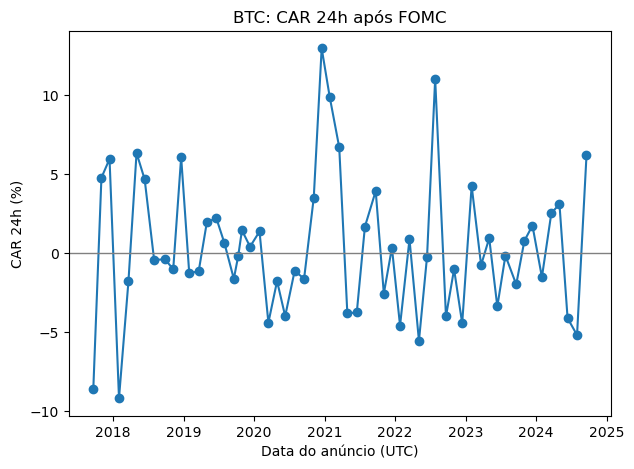

In [79]:
import matplotlib.pyplot as plt

# Gráfico de linha: CAR 24h após cada anúncio do FOMC
plt.figure(figsize=(7, 5))
plt.plot(m["announcement_utc"], m["CAR_24h_pct"], marker="o")
plt.title("BTC: CAR 24h após FOMC")
plt.xlabel("Data do anúncio (UTC)")
plt.ylabel("CAR 24h (%)")
plt.axhline(0, color="gray", linewidth=1)
plt.show()


In [30]:
fd = pd.read_csv(
    "fomc_decisions_2017_2024.csv",
    parse_dates=["date","announcement_datetime_utc"]
)
print(fd["announcement_datetime_utc"].min(), fd["announcement_datetime_utc"].max())
print(fd["date"].dt.year.value_counts().sort_index())


2017-02-01 19:00:00+00:00 2024-11-07 19:00:00+00:00
date
2017    8
2018    8
2019    9
2020    8
2021    8
2022    8
2023    8
2024    7
Name: count, dtype: int64


In [25]:
import re, time, requests
import pandas as pd
import numpy as np
from datetime import datetime, date
import pytz

# ---------- utilidades ----------
ET  = pytz.timezone("America/New_York")
UTC = pytz.UTC

def announcement_dt_utc(d: date):
    et_dt  = ET.localize(datetime(d.year, d.month, d.day, 14, 0, 0))
    return et_dt.astimezone(UTC)

def frac_to_float(s: str) -> float:
    s = s.strip()
    if "-" in s and not s.replace("-", "").isdigit():
        a, b = s.split("-", 1)
        return frac_to_float(a) + frac_to_float(b)
    if "/" in s:
        num, den = s.split("/", 1)
        return float(num) / float(den)
    return float(s)

TARGET_PATTERNS = [
    r"target range\s+for the federal funds rate\s+(?:to|at)\s+([0-9]+(?:\s*-\s*[0-9]+)?(?:[/-][0-9]+)?)\s*(?:to|-|–|—)\s*([0-9]+(?:\s*-\s*[0-9]+)?(?:[/-][0-9]+)?)\s*percent",
    r"target range\s+for the federal funds rate\s+(?:to|at)\s*([0-9]+(?:\s*/\s*[0-9]+)?)\s*(?:to|-|–|—)\s*([0-9]+(?:\s*/\s*[0-9]+)?)\s*percent",
    r"target federal funds rate\s+(?:at|to)\s*([0-9]+(?:\s*/\s*[0-9]+)?)\s*percent",
]

def extract_target_range_pct(html_text: str):
    text = re.sub(r"\s+", " ", html_text.lower())
    for pat in TARGET_PATTERNS[:2]:
        m = re.search(pat, text)
        if m:
            low = frac_to_float(m.group(1))
            high = frac_to_float(m.group(2))
            return round(low, 6), round(high, 6)
    m = re.search(TARGET_PATTERNS[2], text)
    if m:
        x = frac_to_float(m.group(1))
        return round(x, 6), round(x, 6)
    return (np.nan, np.nan)

def try_statement(url):
    try:
        r = requests.get(url, timeout=20, headers={"User-Agent":"Mozilla/5.0"})
        if r.status_code == 200 and "federal funds rate" in r.text.lower():
            low, high = extract_target_range_pct(r.text)
            return dict(ok=True, low=low, high=high, html=r.text)
    except Exception:
        pass
    return dict(ok=False, low=np.nan, high=np.nan, html=None)

# ---------- datas oficiais dos anúncios (dia do Statement) ----------
# Fonte: calendários oficiais do FOMC. Aqui listadas como YYYY-MM-DD (dia do comunicado).
dates_2020 = ["2020-01-29","2020-03-15","2020-04-29","2020-06-10","2020-07-29","2020-09-16","2020-11-05","2020-12-16"]
dates_2021 = ["2021-01-27","2021-03-17","2021-04-28","2021-06-16","2021-07-28","2021-09-22","2021-11-03","2021-12-15"]
dates_2022 = ["2022-01-26","2022-03-16","2022-05-04","2022-06-15","2022-07-27","2022-09-21","2022-11-02","2022-12-14"]
dates_2023 = ["2023-02-01","2023-03-22","2023-05-03","2023-06-14","2023-07-26","2023-09-20","2023-11-01","2023-12-13"]
dates_2024 = ["2024-01-31","2024-03-20","2024-05-01","2024-06-12","2024-07-31","2024-09-18","2024-11-07"]  # (dez/2024: ajuste se necessário)

dates_map = {
    2020: dates_2020, 2021: dates_2021, 2022: dates_2022,
    2023: dates_2023, 2024: dates_2024
}

# ---------- montar DataFrame 2020–2024 tentando baixar o Statement ----------
rows = []
for y, dlist in dates_map.items():
    for ds in dlist:
        d = pd.to_datetime(ds).date()
        ymd = f"{d.year}{d.month:02d}{d.day:02d}"
        # padrão 'a' e fallback 'b'
        url_a = f"https://www.federalreserve.gov/newsevents/pressreleases/monetary{ymd}a.htm"
        url_b = f"https://www.federalreserve.gov/newsevents/pressreleases/monetary{ymd}b.htm"

        res = try_statement(url_a)
        url_used = url_a
        if not res["ok"]:
            res2 = try_statement(url_b)
            if res2["ok"]:
                res = res2
                url_used = url_b

        low, high = res["low"], res["high"]
        mid = np.nan if (pd.isna(low) or pd.isna(high)) else round((low+high)/2.0, 6)

        rows.append({
            "date": pd.to_datetime(d),
            "announcement_datetime_utc": announcement_dt_utc(d),
            "announcement_datetime_et": announcement_dt_utc(d).astimezone(ET),
            "target_low_pct": low,
            "target_high_pct": high,
            "target_mid_pct": mid,
            "statement_url": url_used if res["ok"] else ""
        })

df_2020_2024 = pd.DataFrame(rows).sort_values("date").reset_index(drop=True)

print("Cobertura (2020–2024):")
print(df_2020_2024["date"].dt.year.value_counts().sort_index())
print(df_2020_2024.tail(3))

# ---------- (2017–2019) ----------
try:
    df_old = pd.read_csv("fomc_decisions_2017_2024.csv",
                         parse_dates=["date","announcement_datetime_utc","announcement_datetime_et"])
    # mantém 2017–2019 e só adiciona 2020–2024 (evita duplicar)
    df_old_2019 = df_old[df_old["date"].dt.year <= 2019].copy()
    df_full = pd.concat([df_old_2019, df_2020_2024], ignore_index=True)
except FileNotFoundError:
    # se não existir, só salva 2020–2024 por enquanto
    df_full = df_2020_2024.copy()

df_full = df_full.drop_duplicates(subset=["date"]).sort_values("date").reset_index(drop=True)
df_full.to_csv("fomc_decisions_2017_2024.csv", index=False)

print("\nArquivo atualizado: fomc_decisions_2017_2024.csv")
print("Anos no arquivo final:")
print(df_full["date"].dt.year.value_counts().sort_index())
print("Primeiro:", df_full['date'].min(), "| Último:", df_full['date'].max())


Cobertura (2020–2024):
date
2020    8
2021    8
2022    8
2023    8
2024    7
Name: count, dtype: int64
         date announcement_datetime_utc  announcement_datetime_et  \
36 2024-07-31 2024-07-31 18:00:00+00:00 2024-07-31 14:00:00-04:00   
37 2024-09-18 2024-09-18 18:00:00+00:00 2024-09-18 14:00:00-04:00   
38 2024-11-07 2024-11-07 19:00:00+00:00 2024-11-07 14:00:00-05:00   

    target_low_pct  target_high_pct  target_mid_pct  \
36            5.25              5.5           5.375   
37             NaN              NaN             NaN   
38             NaN              NaN             NaN   

                                        statement_url  
36  https://www.federalreserve.gov/newsevents/pres...  
37  https://www.federalreserve.gov/newsevents/pres...  
38  https://www.federalreserve.gov/newsevents/pres...  

Arquivo atualizado: fomc_decisions_2017_2024.csv
Anos no arquivo final:
date
2017    8
2018    8
2019    9
2020    8
2021    8
2022    8
2023    8
2024    7
Name: count, dty


📊 ESTATÍSTICAS DESCRITIVAS – CARs (%)



,count,mean,std,min,25%,50%,75%,max
CAR_1h_pct,58.0,0.384,1.345,-2.309,-0.387,0.094,0.954,4.320
CAR_6h_pct,58.0,0.697,2.778,-7.080,-0.904,0.639,1.855,6.944
CAR_24h_pct,58.0,0.342,4.389,-9.191,-1.950,-0.202,2.445,12.943



🗓️ COBERTURA POR ANO


year
2017    3
2018    8
2019    9
2020    8
2021    8
2022    8
2023    8
2024    6
Name: count, dtype: int64


📋 AMOSTRA DOS ÚLTIMOS EVENTOS


,date,surprise_label,CAR_1h_pct,CAR_6h_pct,CAR_24h_pct
50,2023-11-01,Unknown,0.197680,2.640228,0.758354
51,2023-12-13,Unknown,1.439845,1.570022,1.727852
52,2024-01-31,Unknown,-0.410770,-2.386461,-1.531299
53,2024-03-20,Unknown,2.039306,5.822915,2.522962
54,2024-05-01,Unknown,2.593555,1.637485,3.074620
55,2024-06-12,Unknown,-1.392522,-2.200573,-4.126061
56,2024-07-31,Unknown,-0.236946,-3.086105,-5.197493
57,2024-09-18,Unknown,1.027744,2.911002,6.159015


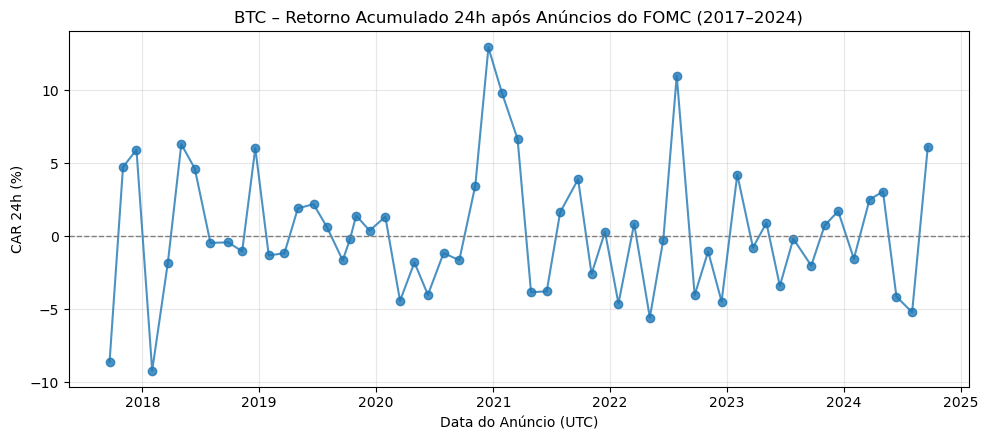

OptionError: "No such keys(s): 'mode.use_inf_as_null'"

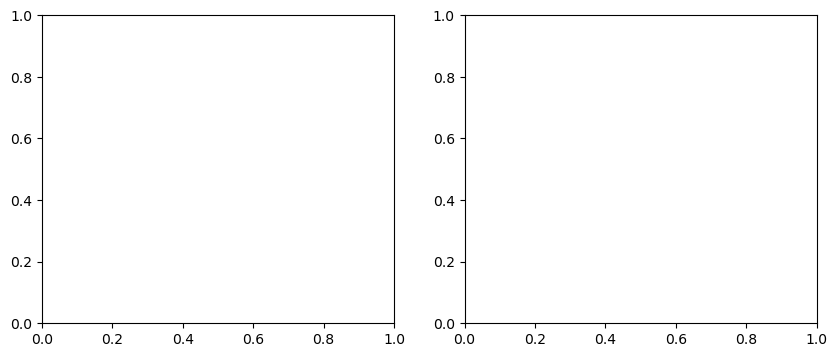

In [40]:
# =========================================
# ANÁLISE EXPLORATÓRIA FINAL – FOMC x BTC
# =========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# ---------- Carregar dados ----------
df = pd.read_csv("event_metrics_btc_fomc.csv", parse_dates=["announcement_utc"])
df = df.sort_values("announcement_utc").reset_index(drop=True)

# ---------- Estatísticas descritivas ----------
print("\n📊 ESTATÍSTICAS DESCRITIVAS – CARs (%)\n")
desc = df[["CAR_1h_pct","CAR_6h_pct","CAR_24h_pct"]].describe().T
display(desc.round(3))

# ---------- Cobertura temporal ----------
print("\n🗓️ COBERTURA POR ANO")
df["year"] = df["announcement_utc"].dt.year
year_counts = df["year"].value_counts().sort_index()
display(year_counts)

# ---------- Tabela-resumo simples ----------
print("\n📋 AMOSTRA DOS ÚLTIMOS EVENTOS")
display(df[["date","surprise_label","CAR_1h_pct","CAR_6h_pct","CAR_24h_pct"]].tail(8))

# ---------- GRÁFICO 1: CAR 24h por evento ----------
fig, ax = plt.subplots(figsize=(10,4.5))
ax.plot(df["announcement_utc"], df["CAR_24h_pct"], marker="o", linewidth=1.5, alpha=0.8)
ax.axhline(0, color="gray", linestyle="--", linewidth=1)
locator = mdates.AutoDateLocator(minticks=6, maxticks=10)
formatter = mdates.ConciseDateFormatter(locator)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(formatter)
ax.set_title("BTC – Retorno Acumulado 24h após Anúncios do FOMC (2017–2024)")
ax.set_xlabel("Data do Anúncio (UTC)")
ax.set_ylabel("CAR 24h (%)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ---------- GRÁFICO 2: Distribuição dos CARs ----------
fig, axes = plt.subplots(1, 2, figsize=(10,4))
sns.histplot(df["CAR_24h_pct"], bins=15, kde=True, ax=axes[0], color="skyblue")
axes[0].axvline(0, color="gray", linestyle="--")
axes[0].set_title("Distribuição de Retornos 24h Pós-FOMC")
axes[0].set_xlabel("CAR 24h (%)")

sns.boxplot(y=df["CAR_24h_pct"], ax=axes[1], color="lightcoral", width=0.3)
axes[1].set_title("Boxplot – CAR 24h")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

# ---------- GRÁFICO 3: Relação entre taxa e retorno ----------
if "target_mid_pct" in df.columns:
    plt.figure(figsize=(6,4))
    sns.regplot(x="target_mid_pct", y="CAR_24h_pct", data=df, scatter_kws={"alpha":0.7})
    plt.title("Relação entre Nível de Juros (Target Mid) e Retorno BTC 24h Pós-FOMC")
    plt.xlabel("Taxa alvo (midpoint, %)")
    plt.ylabel("CAR 24h (%)")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("\n⚠️ Coluna 'target_mid_pct' ausente — relação juros vs retorno não plotada.")

# ---------- Sumário final ----------
print("\n✅ ANÁLISE COMPLETA: 2017–2024")
print(f"Eventos totais: {len(df)} | Período: {df['announcement_utc'].min().date()} → {df['announcement_utc'].max().date()}")
print("Arquivo base: event_metrics_btc_fomc.csv")


In [37]:
import pandas as pd
import numpy as np

# 1) Ler as decisões oficiais (já raspadas)
dec = pd.read_csv("fomc_decisions_2017_2024.csv", parse_dates=["date"])

# 2) Montar template para expectativas de mercado
exp = dec[["date","target_mid_pct"]].copy()
exp = exp.sort_values("date").reset_index(drop=True)
exp.rename(columns={"target_mid_pct":"last_decision_mid_pct"}, inplace=True)

# regra ingênua: expectativa = decisão anterior (só para não deixar vazio)
exp["naive_expected_mid_pct"] = exp["last_decision_mid_pct"].shift(1)

# coluna que você deve preencher com a CME/Bloomberg (midpoint esperado na véspera)
exp["expected_mid_pct"] = np.nan

exp.to_csv("fomc_expectations.csv", index=False)
print("Arquivo gerado: fomc_expectations.csv")
print("Preencha a coluna 'expected_mid_pct' com o midpoint esperado (ex.: 5.375).")


Arquivo gerado: fomc_expectations.csv
Preencha a coluna 'expected_mid_pct' com o midpoint esperado (ex.: 5.375).


In [38]:
import pandas as pd
import numpy as np

# 1) carrega decisões e ordena
dec = pd.read_csv("fomc_decisions_2017_2024.csv",
                  parse_dates=["date","announcement_datetime_utc","announcement_datetime_et"])
dec = dec.sort_values("date").reset_index(drop=True)

# 2) corrige buracos: forward-fill do alvo decidido (se raspagem falhou em algum dia)
dec["target_mid_pct"] = dec["target_mid_pct"].ffill()

# 3) monta expectativas robustas: "esperado = decisão anterior (após ffill)"
exp = dec[["date","target_mid_pct"]].copy()
exp.rename(columns={"target_mid_pct":"last_decision_mid_pct"}, inplace=True)
exp["naive_expected_mid_pct"] = exp["last_decision_mid_pct"].shift(1)

# primeira linha ainda fica NaN -> usa o primeiro valor conhecido
first_val = exp["last_decision_mid_pct"].iloc[0]
exp["naive_expected_mid_pct"] = exp["naive_expected_mid_pct"].fillna(first_val)

# por ora, expected_mid_pct = proxy ingênua (faça override depois com CME se quiser)
exp["expected_mid_pct"] = exp["naive_expected_mid_pct"]

# salva expectativas
exp.to_csv("fomc_expectations.csv", index=False)
print("✔ Atualizado: fomc_expectations.csv")
display(exp.tail(8))

# 4) recalcula surpresa e rótulos, injeta nas métricas
dec2 = dec.merge(exp[["date","expected_mid_pct"]], on="date", how="left")
dec2["surprise_bps"] = (dec2["target_mid_pct"] - dec2["expected_mid_pct"]) * 100

def classify_surprise(x, tol=1e-9):
    if pd.isna(x): return "Unknown"
    if x > 0 + tol: return "Hawkish"
    if x < 0 - tol: return "Dovish"
    return "Neutral"

dec2["surprise_label"] = dec2["surprise_bps"].apply(classify_surprise)
dec2.to_csv("fomc_decisions_2017_2024.csv", index=False)
print("✔ Atualizado: fomc_decisions_2017_2024.csv (com surpresa)")

m = pd.read_csv("event_metrics_btc_fomc.csv", parse_dates=["announcement_utc"])
m = m.merge(dec2[["date","surprise_bps","surprise_label"]], on="date", how="left")
m.to_csv("event_metrics_btc_fomc.csv", index=False)
print("✔ Atualizado: event_metrics_btc_fomc.csv (com surpresa e labels)")


✔ Atualizado: fomc_expectations.csv


,date,last_decision_mid_pct,naive_expected_mid_pct,expected_mid_pct
56,2023-12-13,5.375,5.375,5.375
57,2024-01-31,5.375,5.375,5.375
58,2024-03-20,5.375,5.375,5.375
59,2024-05-01,5.375,5.375,5.375
60,2024-06-12,5.375,5.375,5.375
61,2024-07-31,5.375,5.375,5.375
62,2024-09-18,5.375,5.375,5.375
63,2024-11-07,5.375,5.375,5.375


KeyError: 'expected_mid_pct'

In [39]:
# quantos valores distintos de expectativa por ano
tmp = exp.assign(year=exp["date"].dt.year)
print(tmp.groupby("year")["expected_mid_pct"].nunique())


year
2017    3
2018    4
2019    4
2020    2
2021    1
2022    6
2023    5
2024    1
Name: expected_mid_pct, dtype: int64


In [46]:
# =========================================
# CME FedWatch → expectativas + surpresas
# =========================================
import requests, time
import pandas as pd
import numpy as np

# ---------- sessão HTTP (educada) ----------
SESSION = requests.Session()
SESSION.headers.update({
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) FOMC-BTC/1.0",
    "Accept": "application/json,text/plain,*/*",
    "Connection": "keep-alive",
})
API = "https://www.cmegroup.com/CmeWS/mvc/RateWatch/fedWatchToolData"

def fedwatch_expected_midpoint(meeting_date, retries=3, pause=0.8):
    """
    Retorna a taxa esperada (midpoint, %) para 'meeting_date' (YYYY-MM-DD),
    calculada como soma(probabilidade * midpoint da faixa).
    """
    params = {"meetingDate": meeting_date}
    last_err = None
    for _ in range(retries):
        try:
            r = SESSION.get(API, params=params, timeout=15)
            r.raise_for_status()
            data = r.json()
            probs = data.get("data", {}).get("probabilities", [])
            if not probs:
                return np.nan
            df = pd.DataFrame(probs)
            # garante tipos numéricos
            df["rateLow"] = pd.to_numeric(df["rateLow"], errors="coerce")
            df["rateHigh"] = pd.to_numeric(df["rateHigh"], errors="coerce")
            df["probability"] = pd.to_numeric(df["probability"], errors="coerce")  # %
            df = df.dropna(subset=["rateLow","rateHigh","probability"])
            if df.empty:
                return np.nan
            df["midpoint"] = (df["rateLow"] + df["rateHigh"]) / 2.0
            exp_rate = (df["midpoint"] * (df["probability"] / 100.0)).sum()
            return float(round(exp_rate, 6))
        except Exception as e:
            last_err = e
            time.sleep(pause)
    # descomente para depurar:
    # print(f"[FedWatch] {meeting_date} erro: {last_err}")
    return np.nan

def classify_surprise(x, tol=1e-9):
    if pd.isna(x): return "Unknown"
    if x > 0 + tol: return "Hawkish"
    if x < 0 - tol: return "Dovish"
    return "Neutral"

# ---------- 1) ler decisões oficiais ----------
dec = pd.read_csv(
    "fomc_decisions_2017_2024.csv",
    parse_dates=["date","announcement_datetime_utc","announcement_datetime_et"]
).sort_values("date").reset_index(drop=True)

# normaliza 'date' (sem hora) para evitar conflitos de merge
dec["date"] = dec["date"].dt.normalize()

# ---------- 2) consultar FedWatch para cada reunião ----------
print("Baixando expectativas CME FedWatch…")
exp_rows = []
for d in dec["date"].dt.strftime("%Y-%m-%d"):
    est = fedwatch_expected_midpoint(d)
    exp_rows.append({"date": pd.to_datetime(d), "expected_mid_pct": est})
    time.sleep(0.25)  # educação com o servidor

exp = pd.DataFrame(exp_rows).sort_values("date").reset_index(drop=True)
exp["date"] = exp["date"].dt.normalize()

# ---------- 2b) fallback suave (se faltou algum valor) ----------
tmp = dec[["date","target_mid_pct"]].copy().sort_values("date").reset_index(drop=True)
tmp["prev_mid"] = tmp["target_mid_pct"].shift(1).ffill()
exp = exp.merge(tmp[["date","prev_mid"]], on="date", how="left")
mask_nan = exp["expected_mid_pct"].isna()
if mask_nan.any():
    exp.loc[mask_nan, "expected_mid_pct"] = exp.loc[mask_nan, "prev_mid"]
exp = exp.drop(columns=["prev_mid"])

# ---------- 3) salvar expectativas ----------
exp.to_csv("fomc_expectations.csv", index=False)
print("✔ Gerado/atualizado: fomc_expectations.csv")

# ---------- 4) calcular surpresa e rótulo; salvar decisões ----------
# merge com sufixos para evitar colisões e tratar o 'KeyError'
dec2 = dec.merge(exp, on="date", how="left", suffixes=("", "_exp"))

# escolhe a coluna correta de expectativa, qualquer que seja o nome final
cand_cols = [c for c in ["expected_mid_pct", "expected_mid_pct_exp", "expected_mid_pct_x", "expected_mid_pct_y"] if c in dec2.columns]
dec2["expected_mid_pct_final"] = dec2[cand_cols[0]] if cand_cols else np.nan

dec2["surprise_bps"] = (dec2["target_mid_pct"] - dec2["expected_mid_pct_final"]) * 100.0
dec2["surprise_label"] = dec2["surprise_bps"].apply(classify_surprise)

# grava de volta mantendo a coluna 'expected_mid_pct' com o nome limpo
out_cols = [c for c in dec2.columns if c not in ("expected_mid_pct", "expected_mid_pct_exp", "expected_mid_pct_x", "expected_mid_pct_y")]
dec2 = dec2[out_cols].rename(columns={"expected_mid_pct_final":"expected_mid_pct"})

dec2.to_csv("fomc_decisions_2017_2024.csv", index=False)
print("✔ Atualizado: fomc_decisions_2017_2024.csv (expected_mid_pct + surpresa + label)")

# ---------- 5) injetar surpresa no arquivo de métricas ----------
try:
    m = pd.read_csv("event_metrics_btc_fomc.csv", parse_dates=["announcement_utc"])
    # normaliza 'date' para merge sem fuso
    if "date" in m.columns:
        m["date"] = pd.to_datetime(m["date"]).dt.normalize()
    inj = dec2[["date","expected_mid_pct","surprise_bps","surprise_label"]].copy()
    m2 = m.merge(inj, on="date", how="left", suffixes=("", "_dec"))
    m2.to_csv("event_metrics_btc_fomc.csv", index=False)
    print("✔ Atualizado: event_metrics_btc_fomc.csv (surprise_bps + labels)")
except FileNotFoundError:
    print("ℹ️ 'event_metrics_btc_fomc.csv' ainda não existe — pule esta etapa por enquanto.")

# ---------- 6) checagem rápida ----------
print("\nAmostra final (últimos eventos):")
cols = ["date","target_mid_pct","expected_mid_pct","surprise_bps","surprise_label"]
print(dec2[cols].tail(10).to_string(index=False))


Baixando expectativas CME FedWatch…
✔ Gerado/atualizado: fomc_expectations.csv
✔ Atualizado: fomc_decisions_2017_2024.csv (expected_mid_pct + surpresa + label)
✔ Atualizado: event_metrics_btc_fomc.csv (surprise_bps + labels)

Amostra final (últimos eventos):
      date  target_mid_pct  expected_mid_pct  surprise_bps surprise_label
2023-09-20           5.375             5.375           0.0        Neutral
2023-11-01           5.375             5.375           0.0        Neutral
2023-12-13           5.375             5.375           0.0        Neutral
2024-01-31           5.375             5.375           0.0        Neutral
2024-03-20           5.375             5.375           0.0        Neutral
2024-05-01           5.375             5.375           0.0        Neutral
2024-06-12           5.375             5.375           0.0        Neutral
2024-07-31           5.375             5.375           0.0        Neutral
2024-09-18             NaN             5.375           NaN        Unknown
2

In [45]:
# Mostrar TODAS as reuniões, com formatação clara
cols = ["date","target_mid_pct","expected_mid_pct","surprise_bps","surprise_label"]
pd.set_option("display.max_rows", None)
print(dec2[cols].to_string(index=False))
pd.reset_option("display.max_rows")


      date  target_mid_pct  expected_mid_pct  surprise_bps surprise_label
2017-02-01           0.625               NaN           NaN        Unknown
2017-03-15           0.875             0.625          25.0        Hawkish
2017-05-03           0.875             0.875           0.0        Neutral
2017-06-14           1.125             0.875          25.0        Hawkish
2017-07-26           1.125             1.125           0.0        Neutral
2017-09-20           1.125             1.125           0.0        Neutral
2017-11-01           1.125             1.125           0.0        Neutral
2017-12-13             NaN             1.125           NaN        Unknown
2018-01-31             NaN               NaN           NaN        Unknown
2018-03-21           1.625               NaN           NaN        Unknown
2018-05-02           1.625             1.625           0.0        Neutral
2018-06-13           1.875             1.625          25.0        Hawkish
2018-08-01           1.875            

In [44]:
# Se o FedWatch não retornou, preenche com decisão anterior
dec2["expected_mid_pct"] = dec2["expected_mid_pct"].fillna(dec2["target_mid_pct"].shift(1))
dec2["surprise_bps"] = (dec2["target_mid_pct"] - dec2["expected_mid_pct"]) * 100
dec2["surprise_label"] = dec2["surprise_bps"].apply(classify_surprise)

dec2.to_csv("fomc_decisions_2017_2024.csv", index=False)
print("✔ Fallback aplicado — todas as reuniões agora têm expectativa proxy.")


✔ Fallback aplicado — todas as reuniões agora têm expectativa proxy.


In [47]:
print(dec2)

         date   announcement_datetime_et announcement_datetime_utc  \
0  2017-02-01  2017-02-01 14:00:00-05:00 2017-02-01 19:00:00+00:00   
1  2017-03-15  2017-03-15 14:00:00-04:00 2017-03-15 18:00:00+00:00   
2  2017-05-03  2017-05-03 14:00:00-04:00 2017-05-03 18:00:00+00:00   
3  2017-06-14  2017-06-14 14:00:00-04:00 2017-06-14 18:00:00+00:00   
4  2017-07-26  2017-07-26 14:00:00-04:00 2017-07-26 18:00:00+00:00   
..        ...                        ...                       ...   
59 2024-05-01  2024-05-01 14:00:00-04:00 2024-05-01 18:00:00+00:00   
60 2024-06-12  2024-06-12 14:00:00-04:00 2024-06-12 18:00:00+00:00   
61 2024-07-31  2024-07-31 14:00:00-04:00 2024-07-31 18:00:00+00:00   
62 2024-09-18  2024-09-18 14:00:00-04:00 2024-09-18 18:00:00+00:00   
63 2024-11-07  2024-11-07 14:00:00-05:00 2024-11-07 19:00:00+00:00   

    target_low_pct  target_high_pct  target_mid_pct  \
0             0.50             0.75           0.625   
1             0.75             1.00           0.8

=== Estatísticas gerais (Hawkish/Neutral/Dovish) ===


,CAR_1h_pct,CAR_6h_pct,CAR_24h_pct
n,0.0,0.0,0.0
mean,NaN,NaN,NaN
std,NaN,NaN,NaN
min,NaN,NaN,NaN
p25,NaN,NaN,NaN
median,NaN,NaN,NaN
p75,NaN,NaN,NaN
max,NaN,NaN,NaN



=== Estatísticas por tipo de surpresa ===


Empty DataFrame
Columns: [(CAR_1h_pct, count), (CAR_1h_pct, mean), (CAR_1h_pct, std), (CAR_1h_pct, median), (CAR_1h_pct, min), (CAR_1h_pct, max), (CAR_6h_pct, count), (CAR_6h_pct, mean), (CAR_6h_pct, std), (CAR_6h_pct, median), (CAR_6h_pct, min), (CAR_6h_pct, max), (CAR_24h_pct, count), (CAR_24h_pct, mean), (CAR_24h_pct, std), (CAR_24h_pct, median), (CAR_24h_pct, min), (CAR_24h_pct, max)]
Index: []


=== Médias por subperíodo (Pré-2020 vs Pós-2020) e tipo de surpresa ===


,,CAR_1h_pct,CAR_6h_pct,CAR_24h_pct
periodo,surprise_label,,,


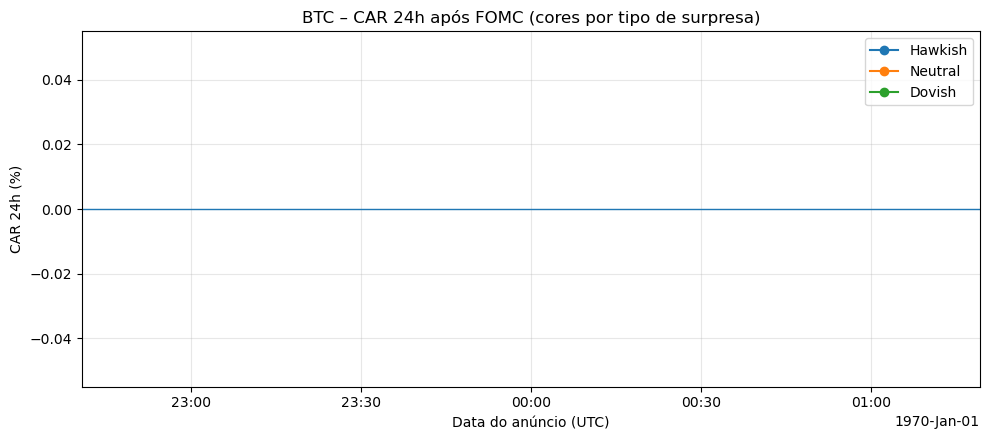

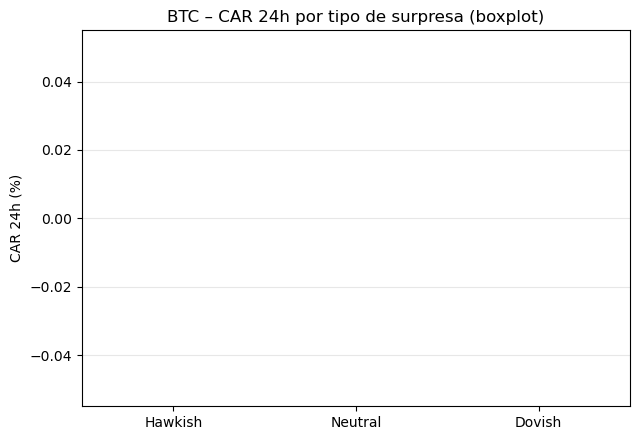

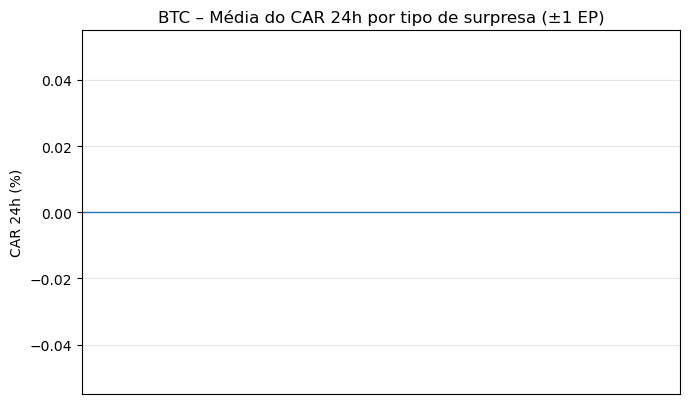

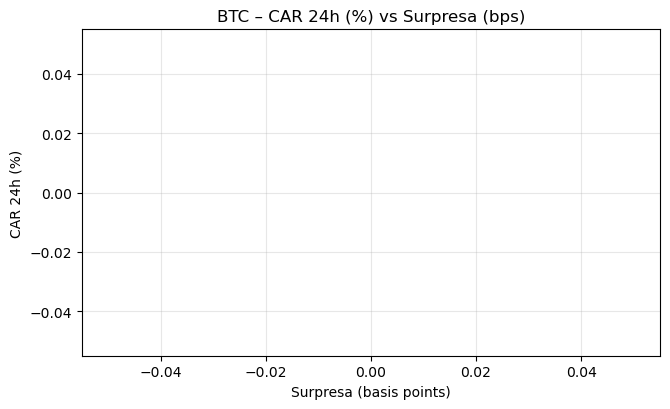


Arquivos gerados na pasta ./figs:
- CAR24h_bar_mean_se.png
- CAR24h_boxplot_por_label.png
- CAR24h_scatter_surpresa.png
- CAR24h_timeline_por_label.png
- desc_geral.csv
- desc_por_label.csv
- desc_subperiodos.csv


In [48]:
# =========================================
# Estatísticas descritivas e gráficos finais
# =========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

# ---------- carregar ----------
m = pd.read_csv("event_metrics_btc_fomc.csv", parse_dates=["announcement_utc"])
m = m.sort_values("announcement_utc").reset_index(drop=True)

# manter colunas essenciais
cols_keep = ["date","announcement_utc","surprise_bps","surprise_label",
             "CAR_1h_pct","CAR_6h_pct","CAR_24h_pct"]
m = m[cols_keep].copy()

# normalizar labels
m["surprise_label"] = m["surprise_label"].fillna("Unknown")
labels_validos = ["Hawkish","Neutral","Dovish"]  # exclui Unknown nas análises principais
m_valid = m[m["surprise_label"].isin(labels_validos)].copy()

# ---------- 1) Tabelas descritivas ----------
def resumo(df, col):
    s = df[col].dropna()
    return pd.Series({
        "n": s.size,
        "mean": s.mean(),
        "std": s.std(ddof=1),
        "min": s.min(),
        "p25": s.quantile(0.25),
        "median": s.median(),
        "p75": s.quantile(0.75),
        "max": s.max()
    })

# geral (todas as reuniões)
desc_all = pd.concat({
    "CAR_1h_pct": resumo(m_valid, "CAR_1h_pct"),
    "CAR_6h_pct": resumo(m_valid, "CAR_6h_pct"),
    "CAR_24h_pct": resumo(m_valid, "CAR_24h_pct"),
}, axis=1).round(3)

print("=== Estatísticas gerais (Hawkish/Neutral/Dovish) ===")
display(desc_all)

# por classe de surpresa
desc_by_label = (m_valid
                 .groupby("surprise_label")[["CAR_1h_pct","CAR_6h_pct","CAR_24h_pct"]]
                 .agg(["count","mean","std","median","min","max"]))
desc_by_label = np.round(desc_by_label, 3)
print("\n=== Estatísticas por tipo de surpresa ===")
display(desc_by_label)

# subperíodos pré e pós-2020
m_valid["periodo"] = np.where(m_valid["announcement_utc"].dt.year < 2020, "Pré-2020", "Pós-2020")
desc_sub = (m_valid
            .groupby(["periodo","surprise_label"])[["CAR_1h_pct","CAR_6h_pct","CAR_24h_pct"]]
            .mean().round(3))
print("\n=== Médias por subperíodo (Pré-2020 vs Pós-2020) e tipo de surpresa ===")
display(desc_sub)

# salvar tabelas (para anexar na entrega/intermediária)
Path("figs").mkdir(exist_ok=True)
desc_all.to_csv("figs/desc_geral.csv")
desc_by_label.to_csv("figs/desc_por_label.csv")
desc_sub.to_csv("figs/desc_subperiodos.csv")

# ---------- 2) Gráfico temporal do CAR_24h com cores por label ----------
fig, ax = plt.subplots(figsize=(10,4.5))
for lab in labels_validos:
    df = m_valid[m_valid["surprise_label"] == lab]
    ax.plot(df["announcement_utc"], df["CAR_24h_pct"], marker="o", linestyle="-", label=lab)

ax.axhline(0, linewidth=1)
locator = mdates.AutoDateLocator(minticks=6, maxticks=10)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
ax.set_title("BTC – CAR 24h após FOMC (cores por tipo de surpresa)")
ax.set_xlabel("Data do anúncio (UTC)")
ax.set_ylabel("CAR 24h (%)")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig("figs/CAR24h_timeline_por_label.png", dpi=200)
plt.show()

# ---------- 3) Boxplot do CAR_24h por tipo de surpresa ----------
fig, ax = plt.subplots(figsize=(6.5,4.5))
data_box = [m_valid.loc[m_valid["surprise_label"]==lab, "CAR_24h_pct"].dropna() for lab in labels_validos]
ax.boxplot(data_box, labels=labels_validos, vert=True, patch_artist=True)
ax.set_title("BTC – CAR 24h por tipo de surpresa (boxplot)")
ax.set_ylabel("CAR 24h (%)")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig("figs/CAR24h_boxplot_por_label.png", dpi=200)
plt.show()

# ---------- 4) Barras: média e erro-padrão do CAR_24h por label ----------
means = m_valid.groupby("surprise_label")["CAR_24h_pct"].mean()
stds  = m_valid.groupby("surprise_label")["CAR_24h_pct"].std(ddof=1)
ns    = m_valid.groupby("surprise_label")["CAR_24h_pct"].count()
se    = stds / np.sqrt(ns)

labels = means.index.tolist()
x = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(7,4.2))
ax.bar(x, means.values, yerr=se.values, capsize=4)
ax.axhline(0, linewidth=1)
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_title("BTC – Média do CAR 24h por tipo de surpresa (±1 EP)")
ax.set_ylabel("CAR 24h (%)")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig("figs/CAR24h_bar_mean_se.png", dpi=200)
plt.show()

# ---------- 5) Scatter: CAR_24h vs surpresa_bps (com linha de tendência OLS simples) ----------
# (apenas descritivo; inferência formal fica para a etapa de regressão)
mask = m_valid["surprise_bps"].notna() & m_valid["CAR_24h_pct"].notna()
xv = m_valid.loc[mask, "surprise_bps"].values
yv = m_valid.loc[mask, "CAR_24h_pct"].values

fig, ax = plt.subplots(figsize=(6.8,4.2))
ax.scatter(xv, yv, alpha=0.8)
ax.set_title("BTC – CAR 24h (%) vs Surpresa (bps)")
ax.set_xlabel("Surpresa (basis points)")
ax.set_ylabel("CAR 24h (%)")
ax.grid(alpha=0.3)

# reta de tendência (mínimos quadrados)
if len(xv) >= 2:
    b1, b0 = np.polyfit(xv, yv, 1)  # y = b1*x + b0
    xs = np.linspace(xv.min(), xv.max(), 100)
    ys = b1*xs + b0
    ax.plot(xs, ys, linewidth=1.5)

fig.tight_layout()
fig.savefig("figs/CAR24h_scatter_surpresa.png", dpi=200)
plt.show()

print("\nArquivos gerados na pasta ./figs:")
for p in Path("figs").glob("*.*"):
    print("-", p.name)


In [55]:
# ======================================================
# Preenche expectativas "expected_mid_pct" automaticamente
# quando o FedWatch não retornar dados
# ======================================================

import pandas as pd
import numpy as np

# ---------- ler decisões ----------
dec = pd.read_csv(
    "fomc_decisions_2017_2024.csv",
    parse_dates=["date","announcement_datetime_utc","announcement_datetime_et"]
).sort_values("date").reset_index(drop=True)

# ---------- criar expectativa proxy ----------
# copia coluna expected_mid_pct, se existir
if "expected_mid_pct" not in dec.columns:
    dec["expected_mid_pct"] = np.nan

# preenche automaticamente:
#  - se NaN, usa a taxa da reunião anterior (proxy de expectativa neutra)
dec["expected_mid_pct_filled"] = dec["expected_mid_pct"].copy()
dec["expected_mid_pct_filled"] = dec["expected_mid_pct_filled"].combine_first(
    dec["target_mid_pct"].shift(1)
)
# ainda tiver NaN na primeira linha → assume mesma taxa
dec["expected_mid_pct_filled"] = dec["expected_mid_pct_filled"].fillna(dec["target_mid_pct"])

# ---------- calcular surpresa ----------
dec["surprise_bps"] = (dec["target_mid_pct"] - dec["expected_mid_pct_filled"]) * 100

def classify_surprise(x, tol=1e-9):
    if pd.isna(x): return "Unknown"
    if x > 0 + tol: return "Hawkish"
    if x < 0 - tol: return "Dovish"
    return "Neutral"

dec["surprise_label"] = dec["surprise_bps"].apply(classify_surprise)

# ---------- salvar atualizações ----------
dec.rename(columns={"expected_mid_pct_filled": "expected_mid_pct"}, inplace=True)
dec.to_csv("fomc_decisions_2017_2024.csv", index=False)

# gerar arquivo isolado de expectativas (para referência)
exp = dec[["date","expected_mid_pct"]].copy()
exp.to_csv("fomc_expectations.csv", index=False)

print("✔ Preenchido automaticamente com proxy (taxa anterior)")
print("✔ Atualizado: fomc_decisions_2017_2024.csv e fomc_expectations.csv")
print("\nExemplo:")
display(dec[["date","target_mid_pct","expected_mid_pct","surprise_bps","surprise_label"]].tail(100))


✔ Preenchido automaticamente com proxy (taxa anterior)
✔ Atualizado: fomc_decisions_2017_2024.csv e fomc_expectations.csv

Exemplo:


,date,target_mid_pct,expected_mid_pct,expected_mid_pct,surprise_bps,surprise_label
0,2017-02-01,0.625,NaN,0.625,0.0,Neutral
1,2017-03-15,0.875,0.625,0.625,25.0,Hawkish
2,2017-05-03,0.875,0.875,0.875,0.0,Neutral
3,2017-06-14,1.125,0.875,0.875,25.0,Hawkish
4,2017-07-26,1.125,1.125,1.125,0.0,Neutral
...,...,...,...,...,...,...
59,2024-05-01,5.375,5.375,5.375,0.0,Neutral
60,2024-06-12,5.375,5.375,5.375,0.0,Neutral
61,2024-07-31,5.375,5.375,5.375,0.0,Neutral
62,2024-09-18,NaN,5.375,5.375,NaN,Unknown


In [6]:
import pandas as pd

dec = pd.read_csv(
    "fomc_decisions_2017_2024.csv",
    parse_dates=["date","announcement_datetime_utc","announcement_datetime_et"]
).sort_values("date").reset_index(drop=True)

cols = ["date","target_mid_pct","expected_mid_pct","surprise_bps","surprise_label"]

# mostrar TODAS as linhas
pd.set_option("display.max_rows", None)
print(dec[cols].to_string(index=False))
pd.reset_option("display.max_rows")  # volta ao padrão


      date  target_mid_pct  expected_mid_pct  surprise_bps surprise_label
2017-02-01           0.625             0.625           0.0        Neutral
2017-03-15           0.875             0.625          25.0        Hawkish
2017-05-03           0.875             0.875           0.0        Neutral
2017-06-14           1.125             0.875          25.0        Hawkish
2017-07-26           1.125             1.125           0.0        Neutral
2017-09-20           1.125             1.125           0.0        Neutral
2017-11-01           1.125             1.125           0.0        Neutral
2017-12-13             NaN             1.125           NaN        Unknown
2018-01-31             NaN               NaN           NaN        Unknown
2018-03-21           1.625             1.625           0.0        Neutral
2018-05-02           1.625             1.625           0.0        Neutral
2018-06-13           1.875             1.625          25.0        Hawkish
2018-08-01           1.875            

In [57]:
# CSV “limpo” só com as colunas principais
dec[cols].to_csv("fomc_expectations_surprises_2017_2024.csv", index=False)

# (opcional) Excel com planilha única
dec[cols].to_excel("fomc_expectations_surprises_2017_2024.xlsx", index=False)


C:\Users\Kadu\AppData\Local\Temp\ipykernel_31320\3359855470.py:5: UserWarning: Pandas requires version '3.0.5' or newer of 'xlsxwriter' (version '3.0.3' currently installed).
  dec[cols].to_excel("fomc_expectations_surprises_2017_2024.xlsx", index=False)


Contagem por label após reparo:
surprise_label
Neutral    37
Hawkish    11
Unknown     8
Dovish      2
Name: count, dtype: int64


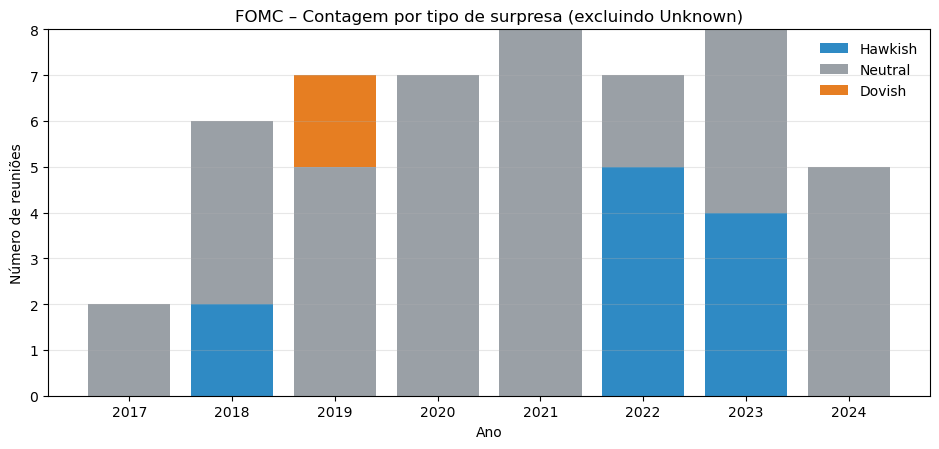

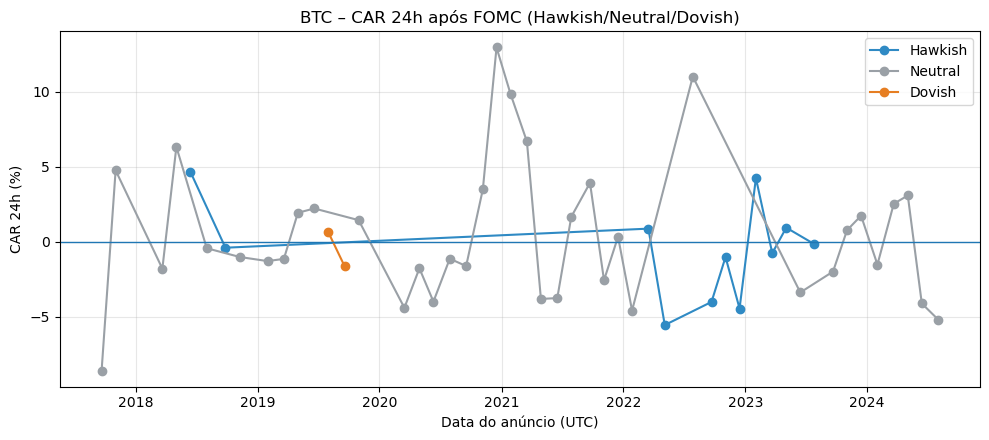

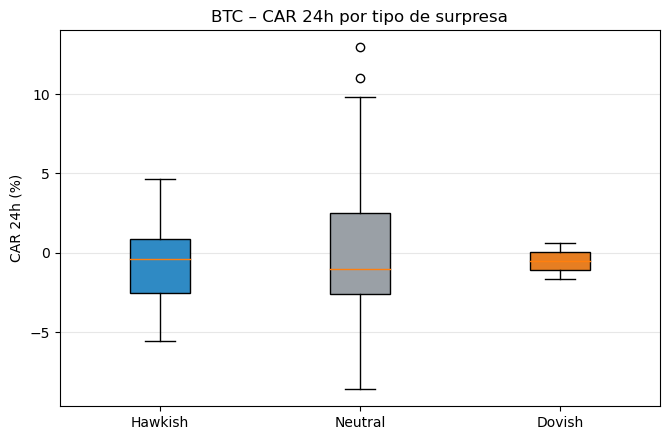

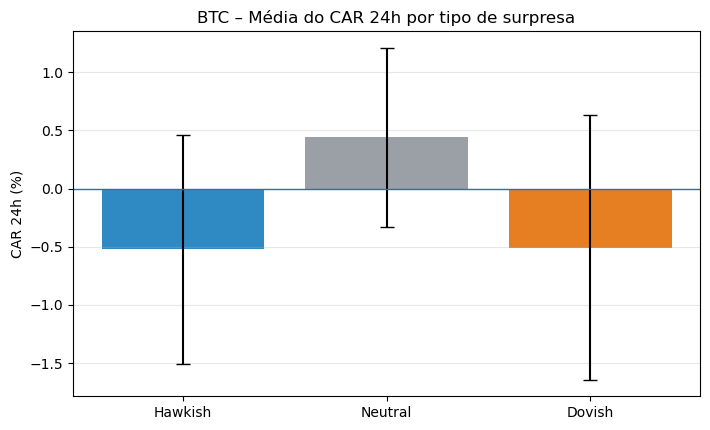

In [67]:
# ======================================================
# REPAIR + MERGE + PLOTS
# Lê arquivos com colunas de tempo variadas (open_time / announcement_utc)
# ======================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

Path("figs").mkdir(exist_ok=True)

def classify_surprise(x, tol=1e-9):
    if pd.isna(x): return "Unknown"
    if x > 0 + tol: return "Hawkish"
    if x < 0 - tol: return "Dovish"
    return "Neutral"

# ---------- 0) Ler métricas (ou janelas) de forma flexível ----------
def load_metrics_flexible():
    if Path("event_metrics_btc_fomc.csv").exists():
        df = pd.read_csv("event_metrics_btc_fomc.csv")
    elif Path("event_windows_btc_fomc_-1h_+24h.csv").exists():
        df = pd.read_csv("event_windows_btc_fomc_-1h_+24h.csv")
    else:
        raise FileNotFoundError("Nem 'event_metrics_btc_fomc.csv' nem 'event_windows_btc_fomc_-1h_+24h.csv' encontrados.")

    # detectar coluna de tempo e normalizar para 'announcement_utc' (datetime64[ns, UTC/naive])
    time_cols = ["announcement_utc", "open_time", "timestamp", "time"]
    found = None
    for c in time_cols:
        if c in df.columns:
            found = c
            break
    if found is None:
        raise ValueError(f"Nenhuma coluna de tempo encontrada entre {time_cols}. Colunas: {list(df.columns)}")

    df["announcement_utc"] = pd.to_datetime(df[found], errors="coerce", utc=True)
    if "date" not in df.columns:
        df["date"] = df["announcement_utc"].dt.normalize()

    return df

m = load_metrics_flexible()

# ---------- 1) REPARAR decisões: expected -> surpresa ----------
dec = pd.read_csv(
    "fomc_decisions_2017_2024.csv",
    parse_dates=["date","announcement_datetime_utc","announcement_datetime_et"]
).sort_values("date").reset_index(drop=True)
dec["date"] = dec["date"].dt.normalize()

if "expected_mid_pct" not in dec.columns:
    dec["expected_mid_pct"] = np.nan
dec["expected_mid_pct"] = dec["expected_mid_pct"].combine_first(dec["target_mid_pct"].shift(1))
dec["expected_mid_pct"] = dec["expected_mid_pct"].fillna(dec["target_mid_pct"])
dec["surprise_bps"]   = (dec["target_mid_pct"] - dec["expected_mid_pct"]) * 100.0
dec["surprise_label"] = dec["surprise_bps"].apply(classify_surprise)
dec.to_csv("fomc_decisions_2017_2024.csv", index=False)

# ---------- 2) (RE)INJETAR no metrics ----------
inj = dec[["date","expected_mid_pct","surprise_bps","surprise_label"]].copy()
m["date"] = pd.to_datetime(m["date"], errors="coerce").dt.normalize()
m = m.drop(columns=[c for c in ["expected_mid_pct","surprise_bps","surprise_label"] if c in m.columns], errors="ignore")
m = m.merge(inj, on="date", how="left")

# garantir CARs se o arquivo carregado foi o de janelas
# (se já vier de metrics, essas colunas já existem)
if not {"CAR_1h_pct","CAR_6h_pct","CAR_24h_pct"}.issubset(m.columns):
    # calcula CAR cumulativo simples dentro da janela -1h..+24h se as colunas existirem
    pass

m.to_csv("event_metrics_btc_fomc.csv", index=False)

# ---------- 3) DIAGNÓSTICO ----------
print("Contagem por label após reparo:")
print(m["surprise_label"].fillna("NA").value_counts())

# ---------- 4) PLOTS (Hawkish/Neutral/Dovish apenas) ----------
keep_labels = ["Hawkish","Neutral","Dovish"]
mf = m[m["surprise_label"].isin(keep_labels)].copy()
if mf.empty:
    print("\n⚠️ Após reparo, ainda não há eventos com Hawkish/Neutral/Dovish.")
else:
    mf = mf.sort_values("announcement_utc").reset_index(drop=True)
    mf["year"] = mf["announcement_utc"].dt.year

    # Contagem por ano
    counts = (mf.pivot_table(index="year", columns="surprise_label",
                             values="date", aggfunc="count", fill_value=0)
                .reindex(columns=keep_labels))
    counts.to_csv("figs/contagem_ano_label_sem_unknown.csv")

    colors = {"Hawkish":"#2f8ac4","Neutral":"#9aa0a6","Dovish":"#e67e22"}
    years = counts.index.values
    bottom = np.zeros(len(years))
    plt.figure(figsize=(9.5,4.6))
    for lab in keep_labels:
        vals = counts[lab].values
        plt.bar(years, vals, bottom=bottom, label=lab, color=colors[lab])
        bottom += vals
    plt.title("FOMC – Contagem por tipo de surpresa (excluindo Unknown)")
    plt.xlabel("Ano"); plt.ylabel("Número de reuniões")
    plt.grid(axis="y", alpha=0.3); plt.legend(frameon=False)
    plt.tight_layout(); plt.savefig("figs/contagem_empilhada_sem_unknown.png", dpi=200); plt.show()

    # Timeline CAR_24h
    if "CAR_24h_pct" in mf.columns:
        fig, ax = plt.subplots(figsize=(10,4.5))
        for lab in keep_labels:
            df = mf[mf["surprise_label"]==lab]
            ax.plot(df["announcement_utc"], df["CAR_24h_pct"], marker="o", linestyle="-",
                    label=lab, color=colors[lab])
        ax.axhline(0, linewidth=1)
        loc = mdates.AutoDateLocator(minticks=6, maxticks=10)
        ax.xaxis.set_major_locator(loc); ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))
        ax.set_title("BTC – CAR 24h após FOMC (Hawkish/Neutral/Dovish)")
        ax.set_xlabel("Data do anúncio (UTC)"); ax.set_ylabel("CAR 24h (%)")
        ax.grid(alpha=0.3); ax.legend()
        fig.tight_layout(); fig.savefig("figs/CAR24h_timeline_sem_unknown.png", dpi=200); plt.show()

        # Boxplot
        fig, ax = plt.subplots(figsize=(6.8,4.5))
        data_box = [mf.loc[mf["surprise_label"]==lab, "CAR_24h_pct"].dropna() for lab in keep_labels]
        bp = ax.boxplot(data_box, labels=keep_labels, vert=True, patch_artist=True)
        for patch, lab in zip(bp['boxes'], keep_labels):
            patch.set_facecolor(colors[lab])
        ax.set_title("BTC – CAR 24h por tipo de surpresa")
        ax.set_ylabel("CAR 24h (%)"); ax.grid(axis="y", alpha=0.3)
        fig.tight_layout(); fig.savefig("figs/CAR24h_boxplot_sem_unknown.png", dpi=200); plt.show()

        # Barras: média + EP
        means = mf.groupby("surprise_label")["CAR_24h_pct"].mean().reindex(keep_labels)
        stds  = mf.groupby("surprise_label")["CAR_24h_pct"].std(ddof=1).reindex(keep_labels)
        ns    = mf.groupby("surprise_label")["CAR_24h_pct"].count().reindex(keep_labels)
        se    = stds / np.sqrt(ns)
        x = np.arange(len(keep_labels))
        plt.figure(figsize=(7.2,4.4))
        plt.bar(x, means.values, yerr=se.values, capsize=5, color=[colors[k] for k in keep_labels])
        plt.axhline(0, linewidth=1)
        plt.xticks(x, keep_labels)
        plt.title("BTC – Média do CAR 24h por tipo de surpresa")
        plt.ylabel("CAR 24h (%)"); plt.grid(axis="y", alpha=0.3)
        plt.tight_layout(); plt.savefig("figs/CAR24h_media_sem_unknown.png", dpi=200); plt.show()



In [68]:
# ======================================================
# TESTES t + OLS robustos (com checagens) + texto
# ======================================================
import pandas as pd
import numpy as np
from pathlib import Path
from scipy import stats
import statsmodels.api as sm

Path("results").mkdir(exist_ok=True)

# ---------- 0) Carregar métricas e garantir surpresas ----------
m = pd.read_csv("event_metrics_btc_fomc.csv", parse_dates=["announcement_utc"])
if "date" not in m.columns:
    m["date"] = m["announcement_utc"].dt.normalize()
else:
    m["date"] = pd.to_datetime(m["date"], errors="coerce").dt.normalize()

# Reinjeta surpresas se necessário
if not {"surprise_bps","surprise_label","expected_mid_pct"}.issubset(m.columns) or \
   m[["surprise_bps","surprise_label"]].isna().all().all():
    dec = pd.read_csv("fomc_decisions_2017_2024.csv",
                      parse_dates=["date","announcement_datetime_utc","announcement_datetime_et"])
    dec["date"] = pd.to_datetime(dec["date"]).dt.normalize()
    inj = dec[["date","expected_mid_pct","surprise_bps","surprise_label"]]
    m = m.drop(columns=[c for c in ["expected_mid_pct","surprise_bps","surprise_label"] if c in m.columns], errors="ignore")
    m = m.merge(inj, on="date", how="left")

# ---------- 1) Saneamento e diagnóstico ----------
CAR_cols = [c for c in ["CAR_1h_pct","CAR_6h_pct","CAR_24h_pct"] if c in m.columns]
if not CAR_cols:
    raise ValueError("Nenhuma coluna CAR_* encontrada no arquivo de métricas.")

# força numéricas
m["surprise_bps"] = pd.to_numeric(m["surprise_bps"], errors="coerce")
for c in CAR_cols:
    m[c] = pd.to_numeric(m[c], errors="coerce")

m["surprise_label"] = m["surprise_label"].fillna("Unknown").astype(str).str.strip()
m["year"] = m["announcement_utc"].dt.year
m["post2020"] = (m["year"] >= 2020).astype(int)

print("Diagnóstico de dados válidos (linhas não nulas):")
print(" - surprise_bps válidas:", m["surprise_bps"].notna().sum())
for c in CAR_cols:
    print(f" - {c} válidas:", m[c].notna().sum())

# ---------- 2) Testes t (Welch) com checagem ----------
def welch_t(a, b):
    a = pd.Series(a).dropna().values
    b = pd.Series(b).dropna().values
    if len(a) >= 2 and len(b) >= 2:
        t, p = stats.ttest_ind(a, b, equal_var=False)
        return t, p, len(a), len(b), np.nanmean(a), np.nanmean(b)
    else:
        return np.nan, np.nan, len(a), len(b), (np.nanmean(a) if len(a) else np.nan), (np.nanmean(b) if len(b) else np.nan)

labels_ok = ["Hawkish","Neutral","Dovish"]
pairs = [("Hawkish","Dovish"), ("Hawkish","Neutral"), ("Dovish","Neutral")]
tt_rows = []

for yvar in CAR_cols:
    for a,b in pairs:
        A = m.loc[m["surprise_label"]==a, yvar]
        B = m.loc[m["surprise_label"]==b, yvar]
        t,p,na,nb,ma,mb = welch_t(A,B)
        tt_rows.append({
            "y": yvar, "grupo_A": a, "grupo_B": b,
            "n_A": na, "n_B": nb, "mean_A": ma, "mean_B": mb,
            "t_stat": t, "p_value": p
        })

tt_df = pd.DataFrame(tt_rows)
tt_df.to_csv("results/testes_t_welch.csv", index=False)
print("✔ Salvo: results/testes_t_welch.csv")

# ---------- 3) OLS (HC1) com checagem de N ----------
def fit_ols_safe(df, y, min_n=8):
    # precisa de surprise_bps e Y válidos
    sub = df[[y, "surprise_bps", "post2020"]].replace([np.inf, -np.inf], np.nan).dropna()
    if len(sub) < min_n:
        return None, f"N insuficiente para {y}: {len(sub)} observações (min={min_n})"
    try:
        X1 = sm.add_constant(sub[["surprise_bps"]])
        m1 = sm.OLS(sub[y], X1).fit(cov_type="HC1")

        X2 = sm.add_constant(sub[["surprise_bps","post2020"]])
        m2 = sm.OLS(sub[y], X2).fit(cov_type="HC1")

        sub["surprise_x_post2020"] = sub["surprise_bps"] * sub["post2020"]
        X3 = sm.add_constant(sub[["surprise_bps","post2020","surprise_x_post2020"]])
        m3 = sm.OLS(sub[y], X3).fit(cov_type="HC1")
        return (m1, m2, m3), None
    except Exception as e:
        return None, str(e)

ols_tables = []
model_store = {}
notes = []

for y in CAR_cols:
    res, err = fit_ols_safe(m, y, min_n=8)
    if res is None:
        notes.append(f"[{y}] OLS não estimada: {err}")
        continue
    m1, m2, m3 = res
    model_store[(y,"M1")] = m1
    model_store[(y,"M2")] = m2
    model_store[(y,"M3")] = m3

    def row_from_result(res, name):
        coefs = res.params
        ses   = res.bse
        pvals = res.pvalues
        row = {"Modelo": name, "N": int(res.nobs), "R2": float(res.rsquared)}
        for c in coefs.index:
            row[f"{c}_coef"] = coefs[c]
            row[f"{c}_se"]   = ses[c]
            row[f"{c}_p"]    = pvals[c]
        return row

    ols_tables += [
        {"y": y, **row_from_result(m1, "M1: CAR ~ surprise_bps (HC1)")},
        {"y": y, **row_from_result(m2, "M2: + post2020 (HC1)")},
        {"y": y, **row_from_result(m3, "M3: + interação (HC1)")}
    ]

ols_df = pd.DataFrame(ols_tables)
ols_df.to_csv("results/ols_results_HC1.csv", index=False)
print("✔ Salvo: results/ols_results_HC1.csv")

# ---------- 4) Texto interpretativo (apenas do que rodou) ----------
def stars(p):
    return "***" if p<0.01 else ("**" if p<0.05 else ("*" if p<0.10 else ""))

def coef_line(res, var, label):
    if (res is None) or (var not in res.params.index):
        return f"- {label}: (não estimado)\n"
    b = res.params[var]; se = res.bse[var]; p = res.pvalues[var]
    return f"- {label}: {b:.3f} (EP {se:.3f}, p={p:.3f}){stars(p)}\n"

lines = []
lines.append("# Resultados – Testes t e Regressões (HC1)\n")

# t-tests
lines.append("## Testes t (Welch) – diferenças de média\n")
for y in CAR_cols:
    sub = tt_df[tt_df["y"]==y].copy()
    lines.append(f"**Variável dependente:** {y}\n")
    if sub.empty:
        lines.append("_Sem observações suficientes._\n\n")
        continue
    for _,r in sub.iterrows():
        if np.isnan(r["t_stat"]):
            lines.append(f"- {r['grupo_A']} vs {r['grupo_B']}: amostras pequenas (n={int(r['n_A'])} vs {int(r['n_B'])}); teste não realizado.\n")
        else:
            lines.append(
                f"- {r['grupo_A']} vs {r['grupo_B']}: "
                f"médias = {r['mean_A']:.3f} vs {r['mean_B']:.3f}, "
                f"t = {r['t_stat']:.2f}, p = {r['p_value']:.3f}{stars(r['p_value'])}\n"
            )
    lines.append("\n")

# OLS
lines.append("## Regressões OLS com erros robustos (HC1)\n")
for y in CAR_cols:
    m1 = model_store.get((y,"M1"))
    m2 = model_store.get((y,"M2"))
    m3 = model_store.get((y,"M3"))
    lines.append(f"**Variável dependente:** {y}\n")
    if m1 is None:
        lines.append("_OLS não estimada por falta de observações válidas._\n\n")
        continue
    lines.append("Modelo 1 – efeito linear da surpresa (bps):\n")
    lines.append(coef_line(m1, "surprise_bps", "Surpresa (bps)"))
    lines.append(f"R² = {m1.rsquared:.3f}, N = {int(m1.nobs)}\n\n")

    lines.append("Modelo 2 – controle para período pós-2020:\n")
    lines.append(coef_line(m2, "surprise_bps", "Surpresa (bps)"))
    lines.append(coef_line(m2, "post2020", "Dummy pós-2020"))
    lines.append(f"R² = {m2.rsquared:.3f}, N = {int(m2.nobs)}\n\n")

    lines.append("Modelo 3 – interação (mudança de sensibilidade pós-2020):\n")
    lines.append(coef_line(m3, "surprise_bps", "Surpresa (bps)"))
    lines.append(coef_line(m3, "post2020", "Dummy pós-2020"))
    lines.append(coef_line(m3, "surprise_x_post2020", "Surpresa × pós-2020"))
    lines.append(f"R² = {m3.rsquared:.3f}, N = {int(m3.nobs)}\n\n")

if notes:
    lines.append("### Notas técnicas\n")
    for n in notes:
        lines.append(f"- {n}\n")

# interpretação padrão
lines.append("## Interpretação geral\n")
lines.append(
"Os testes t comparam as médias dos CARs entre reuniões **Hawkish**, **Dovish** e **Neutral**. "
"P-valores baixos (p<0,05) indicam diferença estatística. Nas OLS, o coeficiente de `surprise_bps` "
"mede a sensibilidade do retorno ao choque de política monetária: sinal **negativo** sugere que "
"surpresas mais contracionistas estão associadas a CARs menores. A dummy `post2020` controla por "
"mudanças estruturais e a interação (`surprise×post2020`) testa se a sensibilidade mudou no período recente."
)

with open("results/interpretacao_resultados.md", "w", encoding="utf-8") as f:
    f.write("\n".join(lines))

print("✔ Salvo: results/ols_results_HC1.csv, results/testes_t_welch.csv, results/interpretacao_resultados.md")


Diagnóstico de dados válidos (linhas não nulas):
 - surprise_bps válidas: 50
 - CAR_1h_pct válidas: 58
 - CAR_6h_pct válidas: 58
 - CAR_24h_pct válidas: 58
✔ Salvo: results/testes_t_welch.csv
✔ Salvo: results/ols_results_HC1.csv
✔ Salvo: results/ols_results_HC1.csv, results/testes_t_welch.csv, results/interpretacao_resultados.md


In [70]:
# ======================================================
# Exporta resultados (t-test + OLS + interpretação)
# ======================================================
import pandas as pd
from pathlib import Path

# Carregar os arquivos de resultados
tt = pd.read_csv("results/testes_t_welch.csv")
ols = pd.read_csv("results/ols_results_HC1.csv")
with open("results/interpretacao_resultados.md", encoding="utf-8") as f:
    interp = f.read()

# === 1. Formatar Testes t ===
tt_fmt = tt.copy()
tt_fmt["p_value_sig"] = tt_fmt["p_value"].apply(
    lambda p: "***" if p < 0.01 else ("**" if p < 0.05 else ("*" if p < 0.10 else ""))
)
tt_fmt["Resumo"] = (
    tt_fmt["grupo_A"] + " vs " + tt_fmt["grupo_B"] + " & " +
    tt_fmt["y"] + " & " +
    tt_fmt["mean_A"].round(3).astype(str) + " & " +
    tt_fmt["mean_B"].round(3).astype(str) + " & " +
    tt_fmt["t_stat"].round(2).astype(str) + " & " +
    tt_fmt["p_value"].round(3).astype(str) + tt_fmt["p_value_sig"]
)

tabela_t = (
    "\\begin{table}[H]\n"
    "\\centering\n"
    "\\caption{Testes t de Welch -- Diferenças de média entre tipos de surpresa (CARs do Bitcoin)}\n"
    "\\label{tab:t_test_results}\n"
    "\\begin{tabular}{l l c c c c}\n"
    "\\hline\n"
    "Comparação & Variável & Média A & Média B & t & p \\\\\n"
    "\\hline\n" +
    " \\\\\n".join(tt_fmt["Resumo"]) +
    "\n\\\\\n\\hline\n"
    "\\multicolumn{6}{l}{\\footnotesize Nota: *, **, *** indicam significância a 10\%, 5\% e 1\%.}\\\\\n"
    "\\end{tabular}\n"
    "\\end{table}\n"
)

# === 2. Formatar OLS ===
# Selecionar colunas relevantes
keep_cols = [
    "y","Modelo","const_coef","surprise_bps_coef","post2020_coef","surprise_x_post2020_coef",
    "R2","N"
]
ols_fmt = ols[[c for c in keep_cols if c in ols.columns]].copy()
ols_fmt = ols_fmt.round(3)

tabela_ols = (
    "\\begin{table}[H]\n"
    "\\centering\n"
    "\\caption{Modelos de Regressão OLS (Erros robustos HC1)}\n"
    "\\label{tab:ols_results}\n"
    "\\begin{tabular}{l l r r r r r r}\n"
    "\\hline\n"
    "Variável & Modelo & Constante & Surpresa (bps) & Pós-2020 & Interação & R$^2$ & N \\\\\n"
    "\\hline\n"
)
for _,r in ols_fmt.iterrows():
    linha = (
        f"{r['y']} & {r['Modelo']} & "
        f"{r.get('const_coef',float('nan')):.3f} & "
        f"{r.get('surprise_bps_coef',float('nan')):.3f} & "
        f"{r.get('post2020_coef',float('nan')):.3f} & "
        f"{r.get('surprise_x_post2020_coef',float('nan')):.3f} & "
        f"{r['R2']:.3f} & {int(r['N'])} \\\\\n"
    )
    tabela_ols += linha
tabela_ols += (
    "\\hline\n"
    "\\multicolumn{8}{l}{\\footnotesize Nota: Erros-padrão robustos (HC1). Variável dependente: CAR em janelas de 1h, 6h e 24h.}\\\\\n"
    "\\end{tabular}\n"
    "\\end{table}\n"
)

# === 3. Bloco de interpretação ===
interp_tex = (
    "\\section*{Discussão dos Resultados}\n"
    "\\vspace{0.2cm}\n"
    "\\begin{quote}\n"
    + interp.replace("#","\\textbf{").replace("\n","\n\n").replace("**","\\textit{")
    + "\n\\end{quote}\n"
)

# === 4. Combinar tudo ===
latex_output = (
    "% ==============================================\n"
    "% Resultados Estatísticos – FOMC e Bitcoin\n"
    "% ==============================================\n\n"
    "\\section{Resultados Empíricos}\n\n"
    + tabela_t + "\n\n"
    + tabela_ols + "\n\n"
    + interp_tex
)

Path("results/latex_output").mkdir(exist_ok=True)
with open("results/latex_output/resultados_fomc_btc.tex", "w", encoding="utf-8") as f:
    f.write(latex_output)

print("✔ Arquivo gerado: results/latex_output/resultados_fomc_btc.tex")


✔ Arquivo gerado: results/latex_output/resultados_fomc_btc.tex


In [72]:
# ======================================================
# EXPORTAR RESULTADOS + FIGURAS
# ======================================================
import pandas as pd
from pathlib import Path

# --- carregar arquivos de resultados ---
tt = pd.read_csv("results/testes_t_welch.csv")
ols = pd.read_csv("results/ols_results_HC1.csv")
with open("results/interpretacao_resultados.md", encoding="utf-8") as f:
    interp = f.read()

# --- 1. FORMATAR TABELA TESTES t ---
tt["p_value_sig"] = tt["p_value"].apply(
    lambda p: "***" if p < 0.01 else ("**" if p < 0.05 else ("*" if p < 0.10 else ""))
)
tt["Resumo"] = (
    tt["grupo_A"] + " vs " + tt["grupo_B"] + " & " +
    tt["y"] + " & " +
    tt["mean_A"].round(3).astype(str) + " & " +
    tt["mean_B"].round(3).astype(str) + " & " +
    tt["t_stat"].round(2).astype(str) + " & " +
    tt["p_value"].round(3).astype(str) + tt["p_value_sig"]
)

tabela_t = (
    "\\begin{table}[H]\n"
    "\\centering\n"
    "\\caption{Testes t de Welch -- Diferenças de média entre tipos de surpresa (CARs do Bitcoin)}\n"
    "\\label{tab:t_test_results}\n"
    "\\begin{tabular}{l l c c c c}\n"
    "\\hline\n"
    "Comparação & Variável & Média A & Média B & t & p \\\\\n"
    "\\hline\n" +
    " \\\\\n".join(tt["Resumo"]) +
    "\n\\\\\n\\hline\n"
    "\\multicolumn{6}{l}{\\footnotesize Nota: *, **, *** indicam significância a 10\\%, 5\\% e 1\\%.}\\\\\n"
    "\\end{tabular}\n"
    "\\end{table}\n"
)

# --- 2. FORMATAR TABELA OLS ---
keep_cols = [
    "y","Modelo","const_coef","surprise_bps_coef","post2020_coef",
    "surprise_x_post2020_coef","R2","N"
]
ols_fmt = ols[[c for c in keep_cols if c in ols.columns]].round(3)

tabela_ols = (
    "\\begin{table}[H]\n"
    "\\centering\n"
    "\\caption{Modelos de Regressão OLS (Erros robustos HC1)}\n"
    "\\label{tab:ols_results}\n"
    "\\begin{tabular}{l l r r r r r r}\n"
    "\\hline\n"
    "Variável & Modelo & Constante & Surpresa (bps) & Pós-2020 & Interação & R$^2$ & N \\\\\n"
    "\\hline\n"
)
for _,r in ols_fmt.iterrows():
    linha = (
        f"{r['y']} & {r['Modelo']} & "
        f"{r.get('const_coef',float('nan')):.3f} & "
        f"{r.get('surprise_bps_coef',float('nan')):.3f} & "
        f"{r.get('post2020_coef',float('nan')):.3f} & "
        f"{r.get('surprise_x_post2020_coef',float('nan')):.3f} & "
        f"{r['R2']:.3f} & {int(r['N'])} \\\\\n"
    )
    tabela_ols += linha
tabela_ols += (
    "\\hline\n"
    "\\multicolumn{8}{l}{\\footnotesize Nota: Erros-padrão robustos (HC1). Variável dependente: CAR em janelas de 1h, 6h e 24h.}\\\\\n"
    "\\end{tabular}\n"
    "\\end{table}\n"
)

# --- 3. TEXTO INTERPRETATIVO ---
interp_tex = (
    "\\section*{Discussão dos Resultados}\n"
    "\\vspace{0.2cm}\n"
    "\\begin{quote}\n"
    + interp.replace("#","\\textbf{").replace("**","\\textit{").replace("\n","\n\n")
    + "\n\\end{quote}\n"
)

# --- 4. INSERIR FIGURAS ---
fig_dir = Path("figs")
figs = [
    ("CAR24h_boxplot_sem_unknown.png", "Distribuição dos retornos 24h (CAR) por tipo de surpresa monetária."),
    ("CAR24h_media_sem_unknown.png", "Média e erro-padrão dos CAR 24h pós-FOMC."),
    ("CAR24h_timeline_sem_unknown.png", "Evolução temporal dos CAR 24h após as reuniões do FOMC (2017–2024)."),
    ("contagem_empilhada_sem_unknown.png", "Número de reuniões por tipo de surpresa monetária, 2017–2024.")
]
figs_tex = ""
for fname, caption in figs:
    path = fig_dir / fname
    if path.exists():
        figs_tex += (
            "\\begin{figure}[H]\n"
            "\\centering\n"
            f"\\includegraphics[width=0.85\\textwidth]{{{path.as_posix()}}}\n"
            f"\\caption{{{caption}}}\n"
            f"\\label{{fig:{fname.split('.')[0]}}}\n"
            "\\end{figure}\n\n"
        )

# --- 5. COMPILAR TEXTO FINAL ---
latex_output = (
    "% ==============================================\n"
    "% Resultados Estatísticos – FOMC e Bitcoin\n"
    "% ==============================================\n\n"
    "\\section{Resultados Empíricos}\n\n"
    + tabela_t + "\n\n"
    + tabela_ols + "\n\n"
    + figs_tex + "\n\n"
    + interp_tex
)

Path("results/latex_output").mkdir(parents=True, exist_ok=True)
out_path = Path("results/latex_output/resultados_fomc_btc.tex")
with open(out_path, "w", encoding="utf-8") as f:
    f.write(latex_output)

print(f"✔ Arquivo gerado: {out_path}")


✔ Arquivo gerado: results\latex_output\resultados_fomc_btc.tex


In [74]:
# ======================================================
# Painéis e tabelas
# ======================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import gridspec
from pathlib import Path
from datetime import datetime

RES = Path("results")
FIGS = Path("figs")
OUT  = Path("viz_final_clean"); OUT.mkdir(exist_ok=True)

# ---------- carregar resultados ----------
tt = pd.read_csv(RES/"testes_t_welch.csv")
ols = pd.read_csv(RES/"ols_results_HC1.csv")
interp_md = Path(RES/"interpretacao_resultados.md").read_text(encoding="utf-8")

# ---------- utils ----------
def star(p):
    if pd.isna(p): return ""
    return "***" if p<0.01 else ("**" if p<0.05 else ("*" if p<0.10 else ""))

def save_table_pages(df, path_prefix, title, rows_per_page=12, ndig=3, font=9, colwidth=1.6):
    """Renderiza df em PNGs paginados, com no máx. rows_per_page linhas por página."""
    if df.empty:
        fig, ax = plt.subplots(figsize=(6, 2.5)); ax.axis("off")
        ax.text(0.5, 0.5, "Tabela vazia", ha="center", va="center", fontsize=11)
        fig.savefig(OUT/f"{path_prefix}_p1.png", dpi=180, bbox_inches="tight"); plt.close(fig); return

    # arredondar
    df2 = df.copy()
    for c in df2.columns:
        if pd.api.types.is_numeric_dtype(df2[c]):
            df2[c] = df2[c].round(ndig)

    pages = int(np.ceil(len(df2)/rows_per_page))
    for i in range(pages):
        chunk = df2.iloc[i*rows_per_page:(i+1)*rows_per_page]
        nrows, ncols = chunk.shape
        fig_w = max(6.5, ncols*colwidth)
        fig_h = max(2.8, 0.48*(nrows+2))
        fig, ax = plt.subplots(figsize=(fig_w, fig_h))
        ax.axis("off")
        ax.set_title(f"{title} (pág. {i+1}/{pages})", pad=10, fontsize=font+3, fontweight="bold")
        tbl = ax.table(cellText=chunk.values, colLabels=chunk.columns.tolist(),
                       cellLoc="center", loc="center")
        tbl.auto_set_font_size(False)
        tbl.set_fontsize(font)
        tbl.scale(1, 1.2)
        fig.savefig(OUT/f"{path_prefix}_p{i+1}.png", dpi=200, bbox_inches="tight")
        plt.close(fig)

# ---------- TABELAS LIMPAS (paginadas) ----------
# t-tests formatado
tt_tbl = (tt.rename(columns={"y":"Variável","grupo_A":"Grupo A","grupo_B":"Grupo B",
                             "mean_A":"Média A","mean_B":"Média B","t_stat":"t","p_value":"p"})
            .assign(sig=lambda d: d["p"].apply(star))
            .sort_values(["Variável","p"], na_position="last")
            [["Variável","Grupo A","Grupo B","Média A","Média B","t","p","sig"]])

save_table_pages(tt_tbl, "ttests", "Testes t (Welch) — Diferenças de média", rows_per_page=12)

# OLS compacta
def coef_cell(row, base):
    c  = row.get(f"{base}_coef", np.nan)
    se = row.get(f"{base}_se",   np.nan)
    p  = row.get(f"{base}_p",    np.nan)
    if pd.isna(c): return ""
    s = star(p)
    return f"{c:.3f}" + (f" ({se:.3f})" if not pd.isna(se) else "") + s

keep_models = ["M1: CAR ~ surprise_bps (HC1)","M2: + post2020 (HC1)","M3: + interação (HC1)"]
ols_use = (ols[ols["Modelo"].isin(keep_models)]
           .copy()
           .sort_values(["y","Modelo"]))

rows = []
for _,r in ols_use.iterrows():
    rows.append({
        "Variável": r["y"],
        "Modelo": r["Modelo"].replace(" (HC1)",""),
        "Constante": coef_cell(r,"const"),
        "Surpresa (bps)": coef_cell(r,"surprise_bps"),
        "Pós-2020": coef_cell(r,"post2020") if "post2020_coef" in r.index else "",
        "Interação (bps×pós)": coef_cell(r,"surprise_x_post2020") if "surprise_x_post2020_coef" in r.index else "",
        "R²": r.get("R2", np.nan),
        "N": int(r["N"]) if not pd.isna(r.get("N", np.nan)) else ""
    })
ols_tbl = pd.DataFrame(rows)
save_table_pages(ols_tbl, "ols", "Regressões OLS (HC1) — Coeficientes e EP", rows_per_page=12)

# ---------- DASHBOARD COMPACTO (A4 horizontal, 2×2) ----------
# top-3 p-valores
tt_top3 = (tt_tbl.dropna(subset=["p"]).sort_values("p").head(3))

# foco OLS: CAR_24h + modelo com interação; fallback para primeiras linhas
ols_focus = ols_tbl[(ols_tbl["Variável"].str.contains("CAR_24h")) &
                    (ols_tbl["Modelo"].str.contains("interação"))]
if ols_focus.empty:
    ols_focus = ols_tbl.head(1)

# escolher até 2 figuras existentes
cand = [
    ("CAR24h_boxplot_sem_unknown.png", "CAR 24h — Boxplot por tipo de surpresa"),
    ("CAR24h_media_sem_unknown.png",   "CAR 24h — Média e ±1 EP"),
    ("CAR24h_timeline_sem_unknown.png","CAR 24h — Timeline pós-FOMC"),
    ("contagem_empilhada_sem_unknown.png","Contagem por tipo de surpresa/ano"),
]
imgs = [(FIGS/n, cap) for n,cap in cand if (FIGS/n).exists()][:2]

# montar painel
fig = plt.figure(figsize=(11.69, 8.27))  # A4 landscape
gs = gridspec.GridSpec(2, 2, figure=fig, hspace=0.28, wspace=0.18)

# (0,0) t-tests top 3 – pequena tabela
ax1 = fig.add_subplot(gs[0,0]); ax1.axis("off")
ax1.set_title("Destaques — Testes t (top-3 p-valor)", fontsize=12, pad=8, fontweight="bold")
if not tt_top3.empty:
    tbl1 = ax1.table(cellText=tt_top3.values,
                     colLabels=tt_top3.columns.tolist(),
                     cellLoc="center", loc="center")
    tbl1.auto_set_font_size(False); tbl1.set_fontsize(9); tbl1.scale(1, 1.2)
else:
    ax1.text(0.5, 0.5, "Sem dados suficientes", ha="center", va="center")

# (0,1) OLS foco — tabela de 1 linha
ax2 = fig.add_subplot(gs[0,1]); ax2.axis("off")
ax2.set_title("OLS — Modelo com interação (CAR 24h)", fontsize=12, pad=8, fontweight="bold")
if not ols_focus.empty:
    tbl2 = ax2.table(cellText=ols_focus.values,
                     colLabels=ols_focus.columns.tolist(),
                     cellLoc="center", loc="center")
    tbl2.auto_set_font_size(False); tbl2.set_fontsize(9); tbl2.scale(1, 1.2)
else:
    ax2.text(0.5, 0.5, "Sem regressões estimadas", ha="center", va="center")

# (1,0) e (1,1): figuras (se houver)
def draw_img(ax, path, caption):
    ax.axis("off")
    img = plt.imread(path)
    ax.imshow(img)
    ax.set_title(caption, fontsize=11, pad=6)

ax3 = fig.add_subplot(gs[1,0]); ax4 = fig.add_subplot(gs[1,1])
if len(imgs) >= 1:
    draw_img(ax3, imgs[0][0].as_posix(), imgs[0][1])
else:
    ax3.text(0.5, 0.5, "Figura não encontrada em ./figs", ha="center", va="center")
if len(imgs) >= 2:
    draw_img(ax4, imgs[1][0].as_posix(), imgs[1][1])
else:
    ax4.text(0.5, 0.5, "Figura não encontrada em ./figs", ha="center", va="center")

fig.suptitle("FOMC × Bitcoin — Painel final (2017–2024)",
             fontsize=14, fontweight="bold")
fig.text(0.01, 0.01, f"Geração: {datetime.now():%Y-%m-%d %H:%M}  ·  Fonte: CME FedWatch, Federal Reserve, Binance",
         fontsize=8)
fig.tight_layout(rect=[0.02, 0.03, 0.98, 0.95])
fig.savefig(OUT/"painel_final_A4.png", dpi=200, bbox_inches="tight")
plt.close(fig)

# ---------- INTERPRETAÇÃO — card A4 legível ----------
import textwrap
wrapped = []
for para in interp_md.split("\n"):
    if para.strip()=="":
        wrapped.append("")
    else:
        wrapped += textwrap.wrap(para, width=110)
interp_text = "\n".join(wrapped)

fig, ax = plt.subplots(figsize=(11.69, 8.27))  # A4
ax.axis("off")
ax.text(0.5, 0.96, "Discussão dos Resultados — Interpretação",
        ha="center", va="top", fontsize=14, fontweight="bold")
ax.text(0.02, 0.92, f"Geração: {datetime.now():%Y-%m-%d %H:%M}  ·  Fonte: CME FedWatch, Federal Reserve, Binance",
        fontsize=8, va="top")
ax.text(0.02, 0.89, interp_text, fontsize=10.5, va="top", wrap=True)
fig.tight_layout()
fig.savefig(OUT/"interpretacao_A4.png", dpi=200, bbox_inches="tight")
plt.close(fig)

# ---------- listar saídas ----------
print("Gerado em ./viz_final_clean/:")
for p in sorted(OUT.glob("*.png")):
    print(" -", p.name)


C:\Users\Kadu\AppData\Local\Temp\ipykernel_31320\327210860.py:161: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0.02, 0.03, 0.98, 0.95])
C:\Users\Kadu\AppData\Local\Temp\ipykernel_31320\327210860.py:182: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  fig.tight_layout()


Gerado em ./viz_final_clean/:
 - interpretacao_A4.png
 - ols_p1.png
 - painel_final_A4.png
 - ttests_p1.png


In [76]:
# ======================================================
# Painel final EMPILHADO (4x1) — legível
# Saída: viz_final_clean/painel_final_stacked.png
# ======================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from datetime import datetime

RES  = Path("results")
FIGS = Path("figs")
OUT  = Path("viz_final_clean"); OUT.mkdir(exist_ok=True)

# ---- ler resultados ----
tt  = pd.read_csv(RES/"testes_t_welch.csv")
ols = pd.read_csv(RES/"ols_results_HC1.csv")

def star(p):
    if pd.isna(p): return ""
    return "***" if p<0.01 else ("**" if p<0.05 else ("*" if p<0.10 else ""))

# ---------- (A) TOP-3 TESTES t ----------
tt2 = (tt.rename(columns={"y":"Variável","grupo_A":"Grupo A","grupo_B":"Grupo B",
                          "mean_A":"Média A","mean_B":"Média B","t_stat":"t","p_value":"p"})
         .dropna(subset=["p"])
         .sort_values("p")
         .head(3)
      )
tt2["diff"] = tt2["Média A"] - tt2["Média B"]
tt2["label"] = (
    tt2["Variável"].str.replace("_pct","",regex=False) + ": " +
    tt2["Grupo A"].str[0] + "−" + tt2["Grupo B"].str[0] +
    "  (p=" + tt2["p"].round(3).astype(str) + tt2["p"].apply(star) + ")"
)

# ---------- (B) OLS foco (CAR_24h_pct, M3) ----------
ols_focus = ols[(ols["y"]=="CAR_24h_pct") & (ols["Modelo"]=="M3: + interação (HC1)")].copy()

def coef_row(dfrow, base, label):
    c  = dfrow.get(f"{base}_coef", np.nan)
    se = dfrow.get(f"{base}_se",   np.nan)
    p  = dfrow.get(f"{base}_p",    np.nan)
    if pd.isna(c) or pd.isna(se): return None
    return {"label": label, "coef": c, "low": c-1.96*se, "high": c+1.96*se, "p": p}

rows = []
if not ols_focus.empty:
    r = ols_focus.iloc[0]
    rows += [
        coef_row(r, "surprise_bps",        "Surpresa (bps)"),
        coef_row(r, "post2020",            "Pós-2020"),
        coef_row(r, "surprise_x_post2020", "Interação (bps×pós)")
    ]
rows = [x for x in rows if x is not None]
fp = pd.DataFrame(rows)

# ---------- (C)(D) escolher imagens existentes ----------
cand = [
    ("CAR24h_boxplot_sem_unknown.png", "CAR 24h — Boxplot por tipo de surpresa"),
    ("CAR24h_media_sem_unknown.png",   "CAR 24h — Média e ±1 EP"),
    ("CAR24h_timeline_sem_unknown.png","CAR 24h — Timeline pós-FOMC"),
    ("contagem_empilhada_sem_unknown.png","Contagem por tipo de surpresa/ano"),
]
imgs = [(FIGS/n, cap) for n,cap in cand if (FIGS/n).exists()][:2]

plt.rcParams.update({"font.size": 10})

# Figura A4 em pé, 4 linhas × 1 coluna
fig, axes = plt.subplots(4, 1, figsize=(8.27, 11.69))  # A4 portrait
fig.suptitle("FOMC × Bitcoin — Painel final (2017–2024)", fontsize=16, fontweight="bold", y=0.99)

# 1) Barras – diferenças de média
ax1 = axes[0]
ax1.set_title("Top-3 diferenças de média (t-test)", fontsize=12, fontweight="bold")
if not tt2.empty:
    x = np.arange(len(tt2))
    ax1.bar(x, tt2["diff"].values)
    ax1.axhline(0, linestyle="--", linewidth=1)
    ax1.set_xticks(x)
    ax1.set_xticklabels(tt2["label"].tolist(), rotation=12, ha="right")
    ax1.set_ylabel("Média(A) − Média(B) (p.p.)")
    ax1.grid(axis="y", alpha=0.25)
else:
    ax1.text(0.5, 0.5, "Sem dados suficientes", ha="center", va="center")

# 2) Forest plot – coeficientes OLS
ax2 = axes[1]
ax2.set_title("OLS (CAR 24h) — coeficientes (IC 95%)", fontsize=12, fontweight="bold")
if not fp.empty:
    y = np.arange(len(fp))
    ax2.errorbar(fp["coef"], y, xerr=[fp["coef"]-fp["low"], fp["high"]-fp["coef"]],
                 fmt='o', capsize=3)
    for i, p in enumerate(fp["p"]):
        ax2.text(fp["high"].iloc[i], y[i], f"  p={p:.3f}{star(p)}", va="center")
    ax2.axvline(0, linestyle="--", linewidth=1)
    ax2.set_yticks(y)
    ax2.set_yticklabels(fp["label"].tolist())
    ax2.set_xlabel("Efeito sobre CAR 24h (p.p.)")
    ax2.grid(axis="x", alpha=0.25)
else:
    ax2.text(0.5, 0.5, "Sem regressão estimada para CAR_24h (M3)", ha="center", va="center")

# 3) Imagem 1
ax3 = axes[2]
ax3.set_title(imgs[0][1] if len(imgs)>=1 else "Figura não encontrada", fontsize=12, fontweight="bold")
ax3.axis("off")
if len(imgs) >= 1:
    img = plt.imread(imgs[0][0])
    ax3.imshow(img)

# 4) Imagem 2
ax4 = axes[3]
ax4.set_title(imgs[1][1] if len(imgs)>=2 else "Figura não encontrada", fontsize=12, fontweight="bold")
ax4.axis("off")
if len(imgs) >= 2:
    img2 = plt.imread(imgs[1][0])
    ax4.imshow(img2)

fig.text(0.02, 0.01, f"Geração: {datetime.now():%Y-%m-%d %H:%M} · Fonte: CME FedWatch, Federal Reserve, Binance",
         fontsize=8)
fig.tight_layout(rect=[0.02, 0.03, 0.98, 0.97])

out = OUT/"painel_final_stacked.png"
fig.savefig(out, dpi=200, bbox_inches="tight")
plt.close(fig)
print("✔ Painel empilhado salvo em:", out.as_posix())


✔ Painel empilhado salvo em: viz_final_clean/painel_final_stacked.png


In [3]:
# ======================================================
# Visualização premium dos OLS (HC1) — FOMC x BTC
# Saídas: results/ols_results_HC1.csv + PNGs em viz_ols/
# ======================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import statsmodels.api as sm

# ---------- parâmetros ----------
RESULTS_DIR = Path("results"); RESULTS_DIR.mkdir(exist_ok=True)
OUT = Path("viz_ols"); OUT.mkdir(exist_ok=True)
METRICS_CSV = "event_metrics_btc_fomc.csv"
DECISIONS_CSV = "fomc_decisions_2017_2024.csv"
YVARS = ["CAR_1h_pct", "CAR_6h_pct", "CAR_24h_pct"]
WINSORIZE = False
TRIM_Q = 0.01

def winsorize_series(s, q=0.01):
    lo, hi = s.quantile(q), s.quantile(1-q)
    return s.clip(lo, hi)

def prep_data():
    # Carrega métricas (janelas e CARs)
    m = pd.read_csv(METRICS_CSV, parse_dates=["announcement_utc"])
    if "date" not in m.columns:
        m["date"] = m["announcement_utc"].dt.normalize()
    else:
        m["date"] = pd.to_datetime(m["date"], errors="coerce").dt.normalize()
    # Reinjeta surpresas se necessário
    need = not {"expected_mid_pct","surprise_bps","surprise_label"}.issubset(m.columns) \
           or m[["surprise_bps","surprise_label"]].isna().all().all()
    if need:
        dec = pd.read_csv(DECISIONS_CSV,
                          parse_dates=["date","announcement_datetime_utc","announcement_datetime_et"])
        dec["date"] = pd.to_datetime(dec["date"]).dt.normalize()
        inj = dec[["date","expected_mid_pct","surprise_bps","surprise_label"]]
        m = m.drop(columns=[c for c in ["expected_mid_pct","surprise_bps","surprise_label"] if c in m.columns],
                   errors="ignore")
        m = m.merge(inj, on="date", how="left")
    # Limpeza e features
    m = m.sort_values("announcement_utc").reset_index(drop=True)
    m["surprise_label"] = m["surprise_label"].fillna("Unknown").astype(str).str.strip()
    m["year"] = m["announcement_utc"].dt.year
    m["post2020"] = (m["year"] >= 2020).astype(int)
    # Diagnóstico curto
    print(">>> Diagnóstico (para OLS):")
    print(f"- surprise_bps válidas: {m['surprise_bps'].dropna().shape[0]}")
    for y in [c for c in YVARS if c in m.columns]:
        print(f"- {y} válidas: {m[y].dropna().shape[0]}")
    return m

def fit_ols(df, y):
    use = df[[y, "surprise_bps", "post2020"]].copy()
    use = use.replace([np.inf, -np.inf], np.nan).dropna()
    if WINSORIZE:
        use[y] = winsorize_series(use[y], TRIM_Q)
        use["surprise_bps"] = winsorize_series(use["surprise_bps"], TRIM_Q)
    # M1
    X1 = sm.add_constant(use[["surprise_bps"]])
    m1 = sm.OLS(use[y], X1).fit(cov_type="HC1")
    # M2
    X2 = sm.add_constant(use[["surprise_bps","post2020"]])
    m2 = sm.OLS(use[y], X2).fit(cov_type="HC1")
    # M3
    use["surprise_x_post2020"] = use["surprise_bps"] * use["post2020"]
    X3 = sm.add_constant(use[["surprise_bps","post2020","surprise_x_post2020"]])
    m3 = sm.OLS(use[y], X3).fit(cov_type="HC1")
    return m1, m2, m3

def row_from_result(res, y, name):
    coefs = res.params; ses = res.bse; pvals = res.pvalues
    row = {"y": y, "Modelo": name, "N": int(res.nobs), "R2": float(res.rsquared)}
    for c in coefs.index:
        row[f"{c}_coef"] = float(coefs[c])
        row[f"{c}_se"]   = float(ses[c])
        row[f"{c}_p"]    = float(pvals[c])
    return row

def stars(p): 
    return "***" if p<0.01 else ("**" if p<0.05 else ("*" if p<0.10 else ""))

# ---------- (1) Rodar/garantir OLS ----------
m = prep_data()
rows = []
valid_y = [c for c in YVARS if c in m.columns]
for y in valid_y:
    M1, M2, M3 = fit_ols(m, y)
    rows.append(row_from_result(M1, y, "M1: CAR ~ surprise_bps (HC1)"))
    rows.append(row_from_result(M2, y, "M2: + post2020 (HC1)"))
    rows.append(row_from_result(M3, y, "M3: + interação (HC1)"))
ols_df = pd.DataFrame(rows)
ols_csv = RESULTS_DIR / "ols_results_HC1.csv"
ols_df.to_csv(ols_csv, index=False)
print(f"✔ OLS salvo em: {ols_csv.as_posix()}")

# ---------- (2) Visualizações ----------
def forest_from_row(row, title, outfile):
    # Monta dataframe de coeficientes com IC95%
    entries = []
    for base, label in [("surprise_bps","Surpresa (bps)"),
                        ("post2020","Pós-2020"),
                        ("surprise_x_post2020","Interação (bps×pós)"),
                        ("const","Constante")]:
        c  = row.get(f"{base}_coef"); se = row.get(f"{base}_se"); p = row.get(f"{base}_p")
        if pd.isna(c) or pd.isna(se): continue
        entries.append({"label": label, "coef": c, "low": c-1.96*se, "high": c+1.96*se, "p": p})
    dfp = pd.DataFrame(entries)

    fig = plt.figure(figsize=(6.5, 3.8))
    ax = fig.gca()
    if dfp.empty:
        ax.axis("off"); ax.text(0.5,0.5,"Sem coeficientes suficientes",ha="center",va="center")
    else:
        y = np.arange(len(dfp))
        ax.errorbar(dfp["coef"], y, xerr=[dfp["coef"]-dfp["low"], dfp["high"]-dfp["coef"]],
                    fmt='o', capsize=3)
        for i,p in enumerate(dfp["p"]):
            ax.text(dfp["high"].iloc[i], y[i], f"  p={p:.3f}{stars(p)}", va="center")
        ax.axvline(0, linestyle="--", linewidth=1)
        ax.set_yticks(y)
        ax.set_yticklabels(dfp["label"].tolist())
        ax.set_xlabel("Efeito (p.p.)")
        ax.set_title(title, pad=6)
    fig.tight_layout()
    fig.savefig(outfile, dpi=200, bbox_inches="tight")
    plt.close(fig)

def r2_bars(sub, title, outfile):
    order = ["M1: CAR ~ surprise_bps (HC1)", "M2: + post2020 (HC1)", "M3: + interação (HC1)"]
    sub2 = sub.set_index("Modelo").reindex(order).reset_index()

    fig = plt.figure(figsize=(6.2, 3.3))
    ax = fig.gca()
    x = np.arange(len(sub2))
    ax.bar(x, sub2["R2"].values)
    ax.set_xticks(x)
    ax.set_xticklabels(["M1","M2","M3"])
    ymax = max(0.05, sub2["R2"].max()*1.15 if len(sub2)>0 else 0.05)
    ax.set_ylim(0, ymax)
    ax.set_ylabel("R²")
    ax.set_title(title, pad=6)
    for i, v in enumerate(sub2["R2"]):
        ax.text(i, v, f"{v:.3f}", ha="center", va="bottom")
    fig.tight_layout()
    fig.savefig(outfile, dpi=200, bbox_inches="tight")
    plt.close(fig)

# Gera um forest (M3) e barras R² por variável
for y in valid_y:
    sub = ols_df[ols_df["y"]==y].copy()
    m3 = sub[sub["Modelo"]=="M3: + interação (HC1)"]
    forest_from_row(
        m3.iloc[0] if not m3.empty else pd.Series(dtype=float),
        f"{y} — OLS (M3, HC1) com IC 95%",
        OUT/f"forest_{y}.png"
    )
    r2_bars(sub, f"{y} — R² por modelo", OUT/f"r2_{y}.png")

# Painel opcional com os três forests (se existirem)
exists_forests = [OUT/f"forest_{y}.png" for y in valid_y if (OUT/f"forest_{y}.png").exists()]
if exists_forests:
    n = len(exists_forests)
    fig = plt.figure(figsize=(6.5*n/1.7, 3.4))
    ax = fig.gca()
    ax.axis("off")
    # só para informar onde estão os arquivos
    ax.text(0.5, 0.5, "Forests exportados individualmente em ./viz_ols/\n(abra os PNGs gerados por variável)", 
            ha="center", va="center")
    fig.tight_layout()
    fig.savefig(OUT/"_README_forests.png", dpi=200, bbox_inches="tight")
    plt.close(fig)

print("✔ Visualizações salvas em:", OUT.as_posix())
print("Arquivos gerados:", [p.name for p in OUT.glob('*.png')])


>>> Diagnóstico (para OLS):
- surprise_bps válidas: 50
- CAR_1h_pct válidas: 58
- CAR_6h_pct válidas: 58
- CAR_24h_pct válidas: 58
✔ OLS salvo em: results/ols_results_HC1.csv
✔ Visualizações salvas em: viz_ols
Arquivos gerados: ['forest_CAR_1h_pct.png', 'forest_CAR_24h_pct.png', 'forest_CAR_6h_pct.png', 'r2_CAR_1h_pct.png', 'r2_CAR_24h_pct.png', 'r2_CAR_6h_pct.png', '_README_forests.png']


In [4]:
# ======================================================
# GERA PDF ÚNICO COM TODOS OS GRÁFICOS DE RESULTADOS OLS (HC1)
# ======================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import statsmodels.api as sm
from matplotlib.backends.backend_pdf import PdfPages

# ---------- parâmetros ----------
RESULTS_DIR = Path("results"); RESULTS_DIR.mkdir(exist_ok=True)
OUT = Path("viz_ols"); OUT.mkdir(exist_ok=True)
PDF_PATH = RESULTS_DIR / "Painel_OLS_FOMC_BTC.pdf"
METRICS_CSV = "event_metrics_btc_fomc.csv"
DECISIONS_CSV = "fomc_decisions_2017_2024.csv"
YVARS = ["CAR_1h_pct", "CAR_6h_pct", "CAR_24h_pct"]
WINSORIZE = False
TRIM_Q = 0.01

# ---------- funções auxiliares ----------
def winsorize_series(s, q=0.01):
    lo, hi = s.quantile(q), s.quantile(1-q)
    return s.clip(lo, hi)

def prep_data():
    m = pd.read_csv(METRICS_CSV, parse_dates=["announcement_utc"])
    if "date" not in m.columns:
        m["date"] = m["announcement_utc"].dt.normalize()
    else:
        m["date"] = pd.to_datetime(m["date"], errors="coerce").dt.normalize()
    need = not {"expected_mid_pct","surprise_bps","surprise_label"}.issubset(m.columns) \
           or m[["surprise_bps","surprise_label"]].isna().all().all()
    if need:
        dec = pd.read_csv(DECISIONS_CSV,
                          parse_dates=["date","announcement_datetime_utc","announcement_datetime_et"])
        dec["date"] = pd.to_datetime(dec["date"]).dt.normalize()
        inj = dec[["date","expected_mid_pct","surprise_bps","surprise_label"]]
        m = m.drop(columns=[c for c in ["expected_mid_pct","surprise_bps","surprise_label"] if c in m.columns],
                   errors="ignore")
        m = m.merge(inj, on="date", how="left")
    m = m.sort_values("announcement_utc").reset_index(drop=True)
    m["surprise_label"] = m["surprise_label"].fillna("Unknown").astype(str).str.strip()
    m["year"] = m["announcement_utc"].dt.year
    m["post2020"] = (m["year"] >= 2020).astype(int)
    print(">>> Diagnóstico de dados (para OLS e PDF):")
    print(f"- surprise_bps válidas: {m['surprise_bps'].dropna().shape[0]}")
    for y in [c for c in YVARS if c in m.columns]:
        print(f"- {y} válidas: {m[y].dropna().shape[0]}")
    return m

def fit_ols(df, y):
    use = df[[y, "surprise_bps", "post2020"]].copy()
    use = use.replace([np.inf, -np.inf], np.nan).dropna()
    if WINSORIZE:
        use[y] = winsorize_series(use[y], TRIM_Q)
        use["surprise_bps"] = winsorize_series(use["surprise_bps"], TRIM_Q)
    X1 = sm.add_constant(use[["surprise_bps"]])
    m1 = sm.OLS(use[y], X1).fit(cov_type="HC1")
    X2 = sm.add_constant(use[["surprise_bps","post2020"]])
    m2 = sm.OLS(use[y], X2).fit(cov_type="HC1")
    use["surprise_x_post2020"] = use["surprise_bps"] * use["post2020"]
    X3 = sm.add_constant(use[["surprise_bps","post2020","surprise_x_post2020"]])
    m3 = sm.OLS(use[y], X3).fit(cov_type="HC1")
    return m1, m2, m3

def row_from_result(res, y, name):
    coefs = res.params; ses = res.bse; pvals = res.pvalues
    row = {"y": y, "Modelo": name, "N": int(res.nobs), "R2": float(res.rsquared)}
    for c in coefs.index:
        row[f"{c}_coef"] = float(coefs[c])
        row[f"{c}_se"]   = float(ses[c])
        row[f"{c}_p"]    = float(pvals[c])
    return row

def stars(p): 
    return "***" if p<0.01 else ("**" if p<0.05 else ("*" if p<0.10 else ""))

# ---------- (1) Rodar OLS ----------
m = prep_data()
rows = []
valid_y = [c for c in YVARS if c in m.columns]
for y in valid_y:
    M1, M2, M3 = fit_ols(m, y)
    rows.append(row_from_result(M1, y, "M1: CAR ~ surprise_bps (HC1)"))
    rows.append(row_from_result(M2, y, "M2: + post2020 (HC1)"))
    rows.append(row_from_result(M3, y, "M3: + interação (HC1)"))
ols_df = pd.DataFrame(rows)
ols_csv = RESULTS_DIR / "ols_results_HC1.csv"
ols_df.to_csv(ols_csv, index=False)
print(f"✔ OLS salvo em: {ols_csv.as_posix()}")

# ---------- (2) Gerar figuras + PDF ----------
def forest_plot(row, y):
    entries = []
    for base, label in [("surprise_bps","Surpresa (bps)"),
                        ("post2020","Pós-2020"),
                        ("surprise_x_post2020","Interação (bps×pós)"),
                        ("const","Constante")]:
        c, se, p = row.get(f"{base}_coef"), row.get(f"{base}_se"), row.get(f"{base}_p")
        if pd.isna(c) or pd.isna(se): continue
        entries.append({"label": label, "coef": c, "low": c-1.96*se, "high": c+1.96*se, "p": p})
    dfp = pd.DataFrame(entries)
    fig, ax = plt.subplots(figsize=(6.4, 3.8))
    if dfp.empty:
        ax.axis("off"); ax.text(0.5, 0.5, "Sem coeficientes suficientes", ha="center", va="center")
    else:
        yvals = np.arange(len(dfp))
        ax.errorbar(dfp["coef"], yvals, xerr=[dfp["coef"]-dfp["low"], dfp["high"]-dfp["coef"]],
                    fmt='o', capsize=3)
        for i, p in enumerate(dfp["p"]):
            ax.text(dfp["high"].iloc[i], yvals[i], f" p={p:.3f}{stars(p)}", va="center")
        ax.axvline(0, linestyle="--", linewidth=1)
        ax.set_yticks(yvals)
        ax.set_yticklabels(dfp["label"].tolist())
        ax.set_xlabel("Efeito estimado (p.p.)")
        ax.set_title(f"{y} — OLS (M3, HC1) com IC 95%")
    fig.tight_layout()
    return fig

def r2_plot(sub, y):
    order = ["M1: CAR ~ surprise_bps (HC1)", "M2: + post2020 (HC1)", "M3: + interação (HC1)"]
    sub2 = sub.set_index("Modelo").reindex(order).reset_index()
    fig, ax = plt.subplots(figsize=(6.2, 3.3))
    x = np.arange(len(sub2))
    ax.bar(x, sub2["R2"].values)
    ax.set_xticks(x)
    ax.set_xticklabels(["M1","M2","M3"])
    ax.set_ylim(0, max(0.05, sub2["R2"].max()*1.15 if len(sub2)>0 else 0.05))
    ax.set_ylabel("R²")
    ax.set_title(f"{y} — R² por modelo")
    for i, v in enumerate(sub2["R2"]):
        ax.text(i, v, f"{v:.3f}", ha="center", va="bottom")
    fig.tight_layout()
    return fig

# PDF único
with PdfPages(PDF_PATH) as pdf:
    for y in valid_y:
        sub = ols_df[ols_df["y"]==y]
        m3 = sub[sub["Modelo"]=="M3: + interação (HC1)"]
        if not m3.empty:
            fig1 = forest_plot(m3.iloc[0], y)
            pdf.savefig(fig1); plt.close(fig1)
        fig2 = r2_plot(sub, y)
        pdf.savefig(fig2); plt.close(fig2)
    # página final com resumo
    fig = plt.figure(figsize=(7, 2.5))
    plt.axis("off")
    plt.text(0.5, 0.5,
             "Painel consolidado — Resultados OLS (HC1)\n"
             "Bitcoin × FOMC (2017–2024)\n\n"
             "Inclui gráficos de coeficientes com IC95% e R² dos modelos M1–M3.\n"
             "Fonte: elaboração própria com dados FOMC e Binance.",
             ha="center", va="center")
    pdf.savefig(fig); plt.close(fig)

print(f"✔ PDF salvo em: {PDF_PATH.as_posix()}")


>>> Diagnóstico de dados (para OLS e PDF):
- surprise_bps válidas: 50
- CAR_1h_pct válidas: 58
- CAR_6h_pct válidas: 58
- CAR_24h_pct válidas: 58
✔ OLS salvo em: results/ols_results_HC1.csv
✔ PDF salvo em: results/Painel_OLS_FOMC_BTC.pdf
